# Do algorithm bans work the same in Llama? — FRLP + C1 demo (task T1, grid path search)

This notebook is a runnable walk-through of `method.py`, the orchestrator of an experiment that replicates a **"ban screen"** on a second model family, **meta-llama/Llama-3.1-8B-Instruct** (bf16, default chat template).

**The question.** If you ask an LLM to *"implement a path search"*, it almost always writes the same algorithm (BFS on a grid). If the prompt then **bans** that algorithm (*"do not use BFS"*), where does the probability mass go?
- Does it move along a **generic ladder**, the same "next most typical" algorithms any prompt perturbation would favour? This is the **LADDER** branch.
- Or does it **substitute** an algorithm specific to the banned one, for example BFS → DFS? This is the **X-specific** / **SUBSTITUTION** branch.

**The instruments** (all numbers come from Llama itself):
- **FRLP (forced-ratio latent probability).** $L_j(c) = \log \operatorname{mean}_m \exp\big[\ell(p_{jm}\mid c) - \ell(p_{jm}\mid F_j)\big]$.
  - It estimates how likely the model is to write algorithm $j$ under prompt $c$.
  - It importance-weights **name-scrubbed programs $p_{jm}$ the model wrote itself** under forced *"Implement $j$"* prompts $F_j$.
  - Each program's log-likelihood $\ell$ was scored with Hugging Face transformers on a GPU.
- **C1 share test.** It splits a single ban's gain profile over the surviving algorithms into two parts:
  - a component along an **external ladder profile $u$**: a nonce ban, matched-norm random edits and a novelty instruction;
  - an **X-specific residual**.
  - $\text{SHARE} = V_s/(V_s+V_u)$ is the noise-corrected X-specific share.
- **Per-sample predictors** of which algorithm a sampled program implements:
  - FRLP top-1 (the method);
  - the *sampled* typicality ladder;
  - the *latent* (FRLP-baseline) ladder;
  - the free-form association answer (*"What is the standard alternative to X?"*).

**What runs here (CPU only, a few minutes).** The notebook starts from the real per-program log-likelihoods of task T1: 156 forced programs × 258 prompt conditions = 23,198 scores, bit-exact.
1. the FRLP cells with their effective sample sizes (ESS);
2. the C1 decomposition, the exact AIM nulls, the ladder test, the template × program bootstrap, the branch decision and the sensitivities (`method.py analyse`, i.e. `src/run_analysis.py`);
3. the per-sample predictor comparison on 100 sampled programs (`method.py outputs`).

**What does not run here.** vLLM generation and HF scoring need a 24 GB GPU (about 0.64 GPU-hours), and the labeller calls an OpenRouter judge. Their outputs are loaded from `mini_demo_data.json`.

**Full-run findings, for orientation.** All are descriptive: two tasks and one model.
- The T1 baseline is *not* collapsed: BFS 77, DFS 20. Banning BFS gives DFS 63/100.
- The FRLP validity gate **fails**: FRLP implies BFS 0.43 against a sampled 0.77.
- C1 under the neutral reference gives SHARE 0.80 (95% CI 0.28–0.94), which is **"not resolved at this N"**. There is no aim and no generic ladder.
- Per sample, the sampled ladder (0.70) beats FRLP top-1 (0.59).

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru -- NOT pre-installed on Colab, always install (method.py logs with it)
_pip('loguru==0.7.3')

# numpy, pandas, scipy, matplotlib -- pre-installed on Colab, install locally only (at Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'pandas==2.2.2', 'scipy==1.16.3', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

# ---- method.py imports (as in the original script)
import argparse
import collections
import json
import subprocess
import sys
import time
from pathlib import Path
from typing import Any

from loguru import logger

# ---- imports of src/analysis_c1.py and src/run_analysis.py, whose code is inlined below
import itertools
import math
from dataclasses import dataclass, field

import numpy as np
import pandas as pd
from scipy.stats import rankdata

# ---- notebook additions: the canon sha256 helper and plotting
import hashlib

import matplotlib.pyplot as plt

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_jSassd-YWLVC/round-2/experiment-10/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()

print(data["description"], "\n")
print(f"examples: {len(data['examples'])} sampled programs from {data['dataset']}")
print("auxiliary inputs (original relative paths):", ", ".join(data["files"]))
ex0 = data["examples"][0]
print(f"\nfirst example: {ex0['row_id']}  label={ex0['label']}  passed={ex0['passed']}  labeller={ex0['labeller_source']}")
print(ex0["code"][:400])

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
Mini demo data for the Llama-3.1-8B-Instruct replication of the FRLP / C1 ban-substitution screen (task T1, grid path search). 'examples' = 100 sampled programs (one dataset: T1_grid_path__llama31_sampled); 'files' = the auxiliary inputs method.py reads, keyed by their original relative path; 'reference' = numbers of the full run for comparison. 

examples: 100 sampled programs from T1_grid_path__llama31_sampled
auxiliary inputs (original relative paths): results/selections.json, results/forced_set_summary.json, results/collapse.json, results/events.json, results/frlp_gate.json, results/c1.json, results/sensitivities.json, results/llama_label_audit.json, results/labeller_recheck.json, results/model_record.json, results/openrouter_cost.json, results/deviations.json, results/frozen_config.json, commitments.log, logs/timing.jsonl, data/forced_set.jsonl, data/free_answers.jsonl, frlp/parts/t1

first example

## Configuration

These are the only knobs. Everything else is the frozen protocol, kept exactly as committed before the first score: the templates W1–W5, `ESS_FLOOR = 5`, the gate thresholds and the event gate.

| knob | meaning | original run |
|---|---|---|
| `N_EXAMPLES` | sampled T1 programs scored by the `outputs` stage (`mini_demo_data.json` holds 100) | 450 T1 + 450 T2 |
| `B` | bootstrap draws for the C1 confidence intervals: templates, plus programs within (algorithm, half) | 2000 (`A.B_DEFAULT`) |
| `B_SENS` | bootstrap draws for each of the 11 sensitivity variants | 400 |
| `TASKS` | tasks analysed. The demo data is T1 only; C1 is T1-only anyway, because T2 keeps 2 survivors per ban | `("t1", "t2")` |

Runtime is driven almost entirely by `B` and `B_SENS`. Each bootstrap draw recomputes every FRLP cell and both C1 references.

At the original values (`B = 2000`, `B_SENS = 400`), the whole notebook takes about 2 minutes on a CPU. That is under 2 minutes of S6 analysis, plus package installs. Lower `B` / `B_SENS` for a quicker look: with `B = 100` the branch decisions already match the full run.

In [5]:
# ---- demo scale (runtime knobs). Whole-notebook runtimes measured in a clean Colab-like venv (CPU):
#      (N_EXAMPLES, B, B_SENS) = (2, 2, 2): 17 s | (25, 100, 20): 21 s | (100, 500, 100): 40 s | (100, 2000, 400): 112 s
N_EXAMPLES = 100  # sampled T1 programs scored by outputs()    (all the demo data holds; original run: 450 T1 + 450 T2)
B = 2000          # C1 bootstrap draws                          (= original A.B_DEFAULT = 2000)
B_SENS = 400      # bootstrap draws per sensitivity variant     (= original main(B_sens=400))

# ---- scope
TASKS = ("t1",)   # original src/run_analysis.TASKS = ("t1", "t2"); the demo data holds task T1 only

## Workspace bridge: files come from `data`

In the original repository, `src/ws.py` puts the copied canonical suite (`canon/`) on `sys.path` and defines the folders `data/`, `frlp/` and `results/`. Every stage then reads and writes files there.

In this notebook the same relative paths are served from the loaded `data`:

- `FILES` maps each original relative path to its content:
  - `data/labelled.jsonl` holds the demo examples, the first `N_EXAMPLES` sampled programs with their mechanism labels;
  - `frlp/parts/t1` holds the per-program score table;
  - `results/*.json` holds the small results files the code reads.
- `read_jsonl` / `read_json` read from `FILES`. `write_json` / `C.write_jsonl` write back into `FILES`, so nothing touches the disk. A later stage reads what an earlier stage "wrote", as in the pipeline.
- `C` stands in for the few `canon/common.py` members that are used: the catalogue order `C.MODES`, the dataset names and the sha256 helper.
- `A` and `RA` stand in for `src/analysis_c1.py` and `src/run_analysis.py`, which the original imports as `A` / `RA`. Their code is inlined below unchanged, so `A.View` and `RA.load_task` simply resolve to the notebook's own definitions.

In [6]:
# ---- src/ws.py, notebook version: the original relative paths, served from `data` instead of the disk
ROOT = Path(".")
DATA, FRLP_DIR, RESULTS = Path("data"), Path("frlp"), Path("results")
MODEL_TAG = "llama-3.1-8b-instruct"

# file contents keyed by their original relative path; the sampled programs (labelled rows) are the demo examples
FILES: dict[str, Any] = {**data["files"], "data/labelled.jsonl": data["examples"][:N_EXAMPLES]}


def read_jsonl(p: Path) -> list[dict[str, Any]]:
    return [dict(r) for r in FILES.get(str(p), [])]


def read_json(p: Path) -> Any:  # notebook: replaces json.loads(p.read_text())
    return FILES[str(p)]


def write_json(p: Path, obj: Any, indent: int | None = 1) -> None:  # notebook: kept in memory
    FILES[str(p)] = obj


def setup_logging(name: str) -> None:
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    # (the original also logs to logs/{name}.log at DEBUG level)


class C:
    """Stand-in for the canon/common.py members used here."""
    MODES = data["catalogue"]["MODES"]  # catalogue order of the algorithms, per task
    TASK_DATASET_NAME = data["catalogue"]["TASK_DATASET_NAME"]

    @staticmethod
    def write_jsonl(p: Path, rows) -> None:  # notebook: kept in memory
        FILES[str(p)] = [dict(r) for r in rows]

    @staticmethod
    def sha256_file(p: Path) -> str:  # sha256 of the file's bytes (its raw text is kept in the demo data)
        return hashlib.sha256(FILES[str(p)].encode()).hexdigest()


class _Inlined:
    """`A.x` / `RA.x` -> the inlined definition of x (src/analysis_c1.py and src/run_analysis.py live in this notebook)."""
    def __getattr__(self, name: str) -> Any:
        return globals()[name]


A = RA = _Inlined()

import warnings  # method.py run() executes every stage as `python -W ignore -m <module>`
warnings.filterwarnings("ignore")
setup_logging("method")
logger.info(f"bridge ready: {len(FILES)} files, {len(FILES['data/labelled.jsonl'])} sampled programs")

10:11:24|INFO   |bridge ready: 19 files, 100 sampled programs


## The orchestrator: `method.py` stages

`method.py` has one sub-command per stage. The stage list below is quoted from its docstring; the last column is added here.

| stage | what it does | where it runs | in this notebook |
|---|---|---|---|
| `setup` | verify the canon copy (`canon/SHA256SUMS`), extract the noun bank, write `results/frozen_config.json` | CPU | input only |
| `recheck` | S0.4 labeller re-check on exp1's adjudicated gold set + 22 references | CPU | reported in metadata |
| `gen PHASE` | S1/S4 vLLM generation (A1..A6, C): 1,780 seeded samples at T = 1.0 | **GPU** | outputs loaded |
| `label` | canonical labeller: runtime probes + AST rules, OpenRouter judge on disagreement only | CPU + **API** | labels loaded |
| `audit` | Llama label audit by a second gold judge | **API** | reported in metadata |
| `forced` | S2 forced set: name scrub, validation, coverage | CPU | forced-set table loaded |
| `score PHASE` | S3/S5 HF scoring of every forced program under every prompt condition (39,768 scores) | **GPU** | T1 scores loaded |
| `commit` | S0.9 hash-chained commitments (frozen config before the first S5 score) | CPU | sha re-checked |
| `analyse` | S6 analysis (`src/run_analysis.py`, frozen) | CPU | **run** (C1 part, T1) |
| `figures`, `rederive` | figures; T11 independent re-derivation | CPU | not run |
| `outputs` | S7 `data/samples.jsonl`, `method_out.json` | CPU | **run** |

The orchestrator code is reproduced verbatim in the next cell. `main()` is defined for reference but not called. The two CPU stages are executed cell by cell further down.

In [7]:
# ---- method.py orchestrator (verbatim). Defined for reference only: the notebook never calls main(), because the GPU
#      and OpenRouter stages cannot run here; the CPU stages `analyse` and `outputs` are executed cell by cell below.
PY = sys.executable


def run(mod: str, *args: str) -> int:
    cmd = [PY, "-W", "ignore", "-m", mod, *args]
    logger.info(f"$ {' '.join(cmd)}")
    return subprocess.call(cmd, cwd=ROOT)


@logger.catch(reraise=True)
def main() -> None:
    ap = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("stage")
    ap.add_argument("arg", nargs="?")
    a = ap.parse_args()
    setup_logging("method")
    s = a.stage
    if s == "setup":
        subprocess.call(["sha256sum", "-c", "--quiet", "SHA256SUMS"], cwd=ROOT / "canon")
        subprocess.call([sys.executable, "-I", "scripts/extract_dependency.py"], cwd=ROOT)
        run("src.commit", "setup-only", "results/frozen_config.json") if False else None
    elif s == "recheck":
        run("src.label_worker", "recheck")
    elif s == "gen":
        run("src.gen_client", "--phase", a.arg)
    elif s == "label":
        run("src.label_worker", "label", *(["--phases", a.arg] if a.arg else []))
    elif s == "audit":
        run("src.label_worker", "audit")
        run("src.label_worker", "audit2")
    elif s == "forced":
        run("src.forced_set")
    elif s == "score":
        run("src.score_session", "--phase", a.arg)
    elif s == "commit":
        run("src.commit", a.arg or "freeze: S0.9 before the first S5 score")
    elif s == "test9":
        run("src.test_analysis_c1")
    elif s == "analyse":
        run("src.run_analysis")
    elif s == "figures":
        run("src.figures")
    elif s == "rederive":
        subprocess.call([PY, "audit/rederive.py"], cwd=ROOT)
    elif s == "outputs":
        outputs()
    else:
        raise SystemExit(f"unknown stage {s}")

## S6 analysis, part 1: the FRLP instrument (`src/analysis_c1.py`, inlined unchanged)

This module was **frozen in `commitments.log` before the first S5 score**. Its docstring:

> FRLP cell $L_j(c) = \text{logmeanexp}_m[\,\ell(p_{jm}\mid c) - \ell(p_{jm}\mid F_j)\,]$ (mixture proposal over the forced prompts used for $j$), ESS $= 1/\sum w^2$ with normalised importance weights. Gains $G^h[X, j, w] = L_j^h(\text{ban}_w X) - L_j^h(\text{neutral}_w^h X)$; prime = mention − neutral; veto = ban − mention. External ladder profile $u$ = mean of the unit-normed, centred nonce, mean-edit and novelty profiles. […]

Two pieces of this cell:

- **`TaskData`** holds, for one task, the program table and two `[P, C]` matrices, `lf` and `lb`:
  - `lf` is the log-likelihood of every forced program $p$ under every prompt condition $c$. `NaN` means not scored.
  - `lb` is the same for the body only, without the closing fence.
- **`proposal()`** gives the importance-sampling proposal $\log q(p) = \ell(p\mid F_j)$.
  - It is the log-mean-exp over the forced paraphrases of the program's own algorithm $j$: 10 *"Implement $j$"* prompts, plus `forced_desc` for the descriptive variant.
  - Programs were sampled from that mixture, so $\exp[\ell(p\mid c)-\ell(p\mid F_j)]$ is an unbiased weight for "how much more likely is this program under $c$ than under the forced prompt".

In [8]:
# ---- src/analysis_c1.py (inlined unchanged)
TEMPLATES = (1, 2, 3, 4, 5)
HALVES = (1, 2)
ESS_FLOOR = 5.0
B_DEFAULT = 2000
GATE = {"a_sigma_lo": 0.3, "a_sigma_hi": 3.0, "a_default_mass": 0.9, "b_nats": 0.3, "c_argmax": 0.8,
        "b_min_nonbanned": 15, "q_other": 0.02, "q_mix": 0.05}
EVENT_GATE = {"avoidance": 0.5, "min_nonbanned": 20, "clear_margin": 0.15}


# ================================================================================================ data
@dataclass
class TaskData:
    task: str
    algs: list[str]  # FRLP-measured algorithms (catalogue order)
    d: str
    s_star: str
    prog: pd.DataFrame  # program_id, j, half, passed, generating_cond (row order of the matrices)
    conds: list[str]
    lf: np.ndarray  # [P, C] l_full (NaN = not scored)
    lb: np.ndarray  # [P, C] l_body
    cidx: dict[str, int] = field(default_factory=dict)
    jidx: np.ndarray | None = None  # [P] algorithm index
    hidx: np.ndarray | None = None  # [P] half index 0/1

    def __post_init__(self):
        self.cidx = {c: i for i, c in enumerate(self.conds)}
        self.jidx = np.array([self.algs.index(j) for j in self.prog["j"]])
        self.hidx = np.array([int(h) - 1 for h in self.prog["half"]])

    def has(self, c: str) -> bool:
        return c in self.cidx


def logmeanexp(a: np.ndarray, axis: int = -1) -> np.ndarray:
    m = np.nanmax(a, axis=axis, keepdims=True)
    m = np.where(np.isfinite(m), m, 0.0)
    with np.errstate(invalid="ignore"):
        e = np.exp(a - m)
    e = np.where(np.isnan(a), 0.0, e)
    n = np.sum(~np.isnan(a), axis=axis, keepdims=True)
    with np.errstate(divide="ignore", invalid="ignore"):
        out = m + np.log(np.sum(e, axis=axis, keepdims=True) / n)
    return np.where(n > 0, out, np.nan).squeeze(axis)


def proposal(td: TaskData, variant: str = "full") -> np.ndarray:
    """log q(p) = l(p | F_j): mixture over every forced prompt used for j (full / body), the generating paraphrase
    ('gen_proposal'), or exp1's 5 standard templates ('exp1_5tpl')."""
    mat = td.lb if variant == "body" else td.lf
    out = np.full(len(td.prog), np.nan)
    pcols = [i for c, i in td.cidx.items() if c.startswith("forced:") or c.startswith("forced_desc:")]
    for r, (j, gen) in enumerate(zip(td.prog["j"], td.prog["generating_cond"])):
        if variant == "gen_proposal":
            out[r] = mat[r, td.cidx[gen]]
            continue
        if variant == "exp1_5tpl":
            cols = [td.cidx[f"forced:{j}:k{k}"] for k in range(5) if f"forced:{j}:k{k}" in td.cidx]
        else:
            cols = [i for i in pcols if td.conds[i].split(":")[1] == j]
        v = mat[r, cols]
        out[r] = logmeanexp(v[~np.isnan(v)]) if np.any(~np.isnan(v)) else np.nan
    return out

### FRLP cells and their effective sample size

`importance()` turns the score matrix into log importance ratios, $D[p, c] = \ell(p\mid c) - \log q(p)$. `make_cells()` then aggregates them per algorithm $j$, for each **half** of the programs (`Lh`, `ESSh`) and pooled (`La`, `ESSa`):

$$L_j(c) = \log \frac{\sum_m w_m e^{D_{jm}(c)}}{\sum_m w_m}, \qquad \text{ESS}_j(c) = \frac{\big(\sum_m w_m e^{D_{jm}}\big)^2}{\sum_m w_m e^{2D_{jm}}}.$$

- The two halves of programs are scored under different neutral nouns ('man' / 'guy'). This gives the split-half replicates used by C1.
- `counts` are bootstrap multiplicities and `mask` selects a program subset. These are the sensitivity variants: correct-only programs, and audit-disputed programs removed.
- A small ESS means one program dominates the cell. The full run had a median cell ESS of 2.5, which is the main source of noise in everything downstream.

In [9]:
# ---- src/analysis_c1.py (inlined unchanged), continued
# ================================================================================================ cells
@dataclass
class Cells:
    Lh: np.ndarray  # [J, 2, C]
    La: np.ndarray  # [J, C]
    ESSh: np.ndarray  # [J, 2, C]
    ESSa: np.ndarray  # [J, C]
    Nh: np.ndarray  # [J, 2] programs per half (with multiplicity)


def make_cells(td: TaskData, D: np.ndarray, counts: np.ndarray | None = None, mask: np.ndarray | None = None) -> Cells:
    """D [P, C] = log importance ratios; counts [P] bootstrap multiplicities; mask [P] program subset."""
    P, C = D.shape
    J = len(td.algs)
    w = np.ones(P) if counts is None else counts.astype(float)
    if mask is not None:
        w = w * mask
    Lh = np.full((J, 2, C), np.nan)
    ESSh = np.full((J, 2, C), np.nan)
    La = np.full((J, C), np.nan)
    ESSa = np.full((J, C), np.nan)
    Nh = np.zeros((J, 2))
    for j in range(J):
        sel_j = td.jidx == j
        Dj = D[sel_j]
        wj = w[sel_j]
        hj = td.hidx[sel_j]
        valid = ~np.isnan(Dj)
        with np.errstate(all="ignore"):
            import warnings
            with warnings.catch_warnings():
                warnings.simplefilter("ignore", RuntimeWarning)
                M = np.nanmax(np.where(valid & (wj[:, None] > 0), Dj, np.nan), axis=0) if np.any(wj > 0) else np.full(C, np.nan)
        M = np.where(np.isfinite(M), M, 0.0)
        E = np.where(valid, np.exp(np.where(valid, Dj, 0.0) - M), 0.0)
        for h in (0, 1):
            sh = (hj == h)
            ww = (wj * sh)[:, None] * valid
            s1 = np.sum(ww * E, axis=0)
            s2 = np.sum(ww * E ** 2, axis=0)
            n = np.sum(ww, axis=0)
            Nh[j, h] = float(np.sum(wj * sh))
            with np.errstate(divide="ignore", invalid="ignore"):
                Lh[j, h] = np.where((n > 0) & (s1 > 0), M + np.log(s1 / n), np.nan)
                ESSh[j, h] = np.where(s2 > 0, s1 ** 2 / s2, np.nan)
        ww = wj[:, None] * valid
        s1 = np.sum(ww * E, axis=0)
        s2 = np.sum(ww * E ** 2, axis=0)
        n = np.sum(ww, axis=0)
        with np.errstate(divide="ignore", invalid="ignore"):
            La[j] = np.where((n > 0) & (s1 > 0), M + np.log(s1 / n), np.nan)
            ESSa[j] = np.where(s2 > 0, s1 ** 2 / s2, np.nan)
    return Cells(Lh=Lh, La=La, ESSh=ESSh, ESSa=ESSa, Nh=Nh)


def importance(td: TaskData, variant: str = "full") -> np.ndarray:
    base = td.lb if variant == "body" else td.lf
    lq = proposal(td, variant if variant in ("body", "gen_proposal", "exp1_5tpl") else "full")
    return base - lq[:, None]

### `View`: gains, prime/veto and the external ladder profile $u$

A `View` reads FRLP values out of one `Cells` object for a template draw `tw` (5 template ids; the bootstrap resamples them). Prompt conditions are named like this:

- `ban:X:w3`: ban X with template W3;
- `mention:X:w3`: the same sentence, mentioning X without banning it;
- `neutral:X:w3:h1`: a length-matched neutral twin, with the half-1 noun;
- `nonce:w3` / `nonce_neutral:w3:h1`: a ban of the made-up *"Zorblax method"*;
- `edit:k1..6`: matched-norm random residual-stream patches on the empty-baseline prompt, applied by hooks on a band of layers;
- `novelty`: *"make it novel"*; `baseline:s0..4`: unbanned prompts.

Quantities:

- **Gain** $G = L(\text{ban}) - L(\text{neutral})$ (or $- L(\text{mention})$ under the mention reference): how much a ban moves each algorithm.
- **Prime** $= L(\text{mention}) - L(\text{neutral})$: the effect of just *naming* X.
- **Generic profiles**: how algorithms move under perturbations that have nothing to do with X (nonce ban, random edits, novelty).
- **$u$** averages the unit-normed, centred nonce, mean-edit and novelty profiles. It is the candidate "typicality ladder" that any perturbation would follow.

In [10]:
# ---- src/analysis_c1.py (inlined unchanged), continued
# ================================================================================================ helpers
def centre(v: np.ndarray) -> np.ndarray:
    return v - np.mean(v)


def unit(v: np.ndarray) -> np.ndarray:
    n = np.linalg.norm(v)
    return v / n if n > 0 else v * np.nan


def cosine(a: np.ndarray, b: np.ndarray) -> float:
    na, nb = np.linalg.norm(a), np.linalg.norm(b)
    return float(a @ b / (na * nb)) if na > 0 and nb > 0 else float("nan")


def spearman(a: np.ndarray, b: np.ndarray) -> float:
    if len(a) < 2 or np.any(np.isnan(a)) or np.any(np.isnan(b)):
        return float("nan")
    ra, rb = rankdata(a), rankdata(b)
    if np.std(ra) == 0 or np.std(rb) == 0:
        return float("nan")
    return float(np.corrcoef(ra, rb)[0, 1])


class View:
    """Accessors over one Cells object with a template draw `tw` (list of 5 template ids)."""

    def __init__(self, td: TaskData, cells: Cells, tw: list[int] | None = None):
        self.td, self.c = td, cells
        self.tw = list(tw) if tw is not None else list(TEMPLATES)
        self.ai = {a: i for i, a in enumerate(td.algs)}

    def h(self, cond: str, h: int, algs: list[str]) -> np.ndarray:
        if cond not in self.td.cidx:
            return np.full(len(algs), np.nan)
        ci = self.td.cidx[cond]
        return np.array([self.c.Lh[self.ai[a], h - 1, ci] for a in algs])

    def a(self, cond: str, algs: list[str]) -> np.ndarray:
        if cond not in self.td.cidx:
            return np.full(len(algs), np.nan)
        ci = self.td.cidx[cond]
        return np.array([self.c.La[self.ai[a], ci] for a in algs])

    def ess_h(self, cond: str, h: int, algs: list[str]) -> np.ndarray:
        if cond not in self.td.cidx:
            return np.full(len(algs), np.nan)
        ci = self.td.cidx[cond]
        return np.array([self.c.ESSh[self.ai[a], h - 1, ci] for a in algs])

    # ---- gains
    def G(self, X: str, w: int, h: int, algs: list[str], ref: str = "neutral") -> np.ndarray:
        ban = self.h(f"ban:{X}:w{w}", h, algs)
        if ref == "neutral":
            return ban - self.h(f"neutral:{X}:w{w}:h{h}", h, algs)
        return ban - self.h(f"mention:{X}:w{w}", h, algs)  # veto row (mention reference)

    def prime(self, X: str, w: int, h: int, algs: list[str]) -> np.ndarray:
        return self.h(f"mention:{X}:w{w}", h, algs) - self.h(f"neutral:{X}:w{w}:h{h}", h, algs)

    # ---- generic profiles over all algorithms
    def generic(self, half: int | None = None) -> dict[str, np.ndarray]:
        algs = self.td.algs
        out: dict[str, np.ndarray] = {}
        hs = HALVES if half is None else (half,)
        out["nonce"] = np.nanmean([self.h(f"nonce:w{w}", h, algs) - self.h(f"nonce_neutral:w{w}:h{h}", h, algs)
                                   for w in self.tw for h in hs], axis=0)
        get = (lambda c: self.a(c, algs)) if half is None else (lambda c: self.h(c, half, algs))
        for k in range(1, 7):
            if self.td.has(f"edit:k{k}"):
                out[f"edit{k}"] = get(f"edit:k{k}") - get("baseline_empty")
        out["novelty"] = get("novelty") - np.nanmean([get(f"baseline:s{s}") for s in range(5)], axis=0)
        return out

    def u(self, half: int | None = None, raw_mean: bool = False) -> np.ndarray:
        g = self.generic(half)
        edits = [g[k] for k in g if k.startswith("edit")]
        if raw_mean:
            return np.mean([g["nonce"]] + edits + [g["novelty"]], axis=0)
        types = [g["nonce"], np.mean(edits, axis=0) if edits else np.full(len(self.td.algs), np.nan), g["novelty"]]
        types = [unit(centre(t)) for t in types if not np.any(np.isnan(t))]
        if not types:  # degenerate bootstrap draw (a half with no programs): undefined profile
            return np.full(len(self.td.algs), np.nan)
        return np.mean(types, axis=0)

## S6 analysis, part 2: loading a task (`src/run_analysis.py`, inlined)

- **`load_task()`** builds `TaskData` from three inputs:
  - the forced set: it drops programs whose original code did not parse, and algorithms with fewer than 10 kept programs (M < 10);
  - the score table, pivoted into `[programs × conditions]` matrices;
  - `results/selections.json`, for the default algorithm $d$ and the modal substitute $s^*$.
- **The one code change**: the original concatenates `frlp/parts/<task>/*.parquet`. Here the same rows come from the long table in `data`. Its float32 values decode bit-exactly to the original scores, as the builder checked.
- **`variant_cells()`** picks the FRLP variant. `full` is the primary; the sensitivity variants are `body`, `gen_proposal`, `exp1_5tpl`, `correct_only` and `audit_disputed_removed`.
- **`write_cells()`** writes the long cell table (`frlp/cells.jsonl`, here kept in memory) that the ESS summary reads. Its per-program parquet export for `audit/rederive.py` is skipped.
- **`association()`** counts the free-form answers to *"What is the standard alternative to X?"*. Llama answers DFS 20/20 for BFS.

In [11]:
# ---- src/run_analysis.py (inlined). File reads go through the bridge; TASKS is set in the config cell.
VARIANTS = ("full", "body", "gen_proposal", "exp1_5tpl", "correct_only")


# ------------------------------------------------------------------------------------------------ loading
def load_task(task: str) -> A.TaskData:
    sel = read_json(RESULTS / "selections.json")
    summ = read_json(RESULTS / "forced_set_summary.json")["per_algorithm"]
    fs = [r for r in read_jsonl(DATA / "forced_set.jsonl") if r["task"] == task and r["scrub_mode"] != "dropped"
          and not summ[f"{task}:{r['j']}"]["excluded_M_lt_10"]]
    order = list(C.MODES[task])
    algs = [j for j in order if any(r["j"] == j for r in fs)]
    fs.sort(key=lambda r: (algs.index(r["j"]), r["half"], r["program_id"]))
    prog = pd.DataFrame([{"program_id": r["program_id"], "j": r["j"], "half": r["half"], "passed": r["passed"],
                          "generating_cond": r["generating_cond"], "n_tokens": r["n_tokens"]} for r in fs])
    # notebook: the rows of frlp/parts/<task>/*.parquet come from `data` (one long table, float32-exact scores)
    # parts = sorted((FRLP_DIR / "parts" / task).glob("*.parquet"))
    # df = pd.concat([pd.read_parquet(p, columns=["program_id", "cond", "l_full", "l_body", "n_tokens"]) for p in parts],
    #                ignore_index=True)
    part = FILES[str(FRLP_DIR / "parts" / task)]
    df = pd.DataFrame({"program_id": [part["programs"][i] for i in part["program_idx"]],
                       "cond": [part["conds"][i] for i in part["cond_idx"]],
                       "l_full": np.asarray(part["l_full"], dtype=np.float32).astype(float),
                       "l_body": np.asarray(part["l_body"], dtype=np.float32).astype(float),
                       "n_tokens": [part["n_tokens"][i] for i in part["program_idx"]]})
    df = df[df["program_id"].isin(set(prog["program_id"]))]
    conds = sorted(df["cond"].unique())
    pf = df.pivot_table(index="program_id", columns="cond", values="l_full", aggfunc="first")
    pb = df.pivot_table(index="program_id", columns="cond", values="l_body", aggfunc="first")
    pf = pf.reindex(index=prog["program_id"], columns=conds)
    pb = pb.reindex(index=prog["program_id"], columns=conds)
    sub = sel[f"{task}_substitute"]["s_star"] if f"{task}_substitute" in sel else None
    return A.TaskData(task=task, algs=algs, d=sel[f"{task}_default"], s_star=sub, prog=prog, conds=conds,
                      lf=pf.to_numpy(dtype=float), lb=pb.to_numpy(dtype=float))


def disputed_rows() -> set[str]:
    p = RESULTS / "llama_label_audit.json"
    return set(read_json(p).get("disputed_row_ids", [])) if str(p) in FILES else set()


def variant_cells(td: A.TaskData, variant: str, counts: np.ndarray | None = None) -> A.Cells:
    base = variant if variant not in ("correct_only", "audit_disputed_removed") else "full"
    D = A.importance(td, base)
    mask = None
    if variant == "correct_only":
        mask = td.prog["passed"].to_numpy(dtype=float)
    elif variant == "audit_disputed_removed":  # plan S1: audit agreement < 0.9 -> C1 without the disputed forced programs
        bad = disputed_rows()
        mask = np.array([0.0 if pid.split("|", 2)[2] in bad else 1.0 for pid in td.prog["program_id"]])
    return A.make_cells(td, D, counts=counts, mask=mask)


def cond_meta(cond: str) -> dict[str, Any]:
    parts = cond.split(":")
    out = {"template": None, "half": None}
    for p in parts[1:]:
        if p.startswith("w") and p[1:].isdigit():
            out["template"] = int(p[1:])
        elif p.startswith("h") and p[1:].isdigit():
            out["half"] = int(p[1:])
        elif p.startswith("s") and p[1:].isdigit():
            out["template"] = f"s{p[1:]}"
        elif p.startswith("p") and p[1:].isdigit():
            out["template"] = f"p{p[1:]}"
        elif p.startswith("k") and p[1:].isdigit():
            out["template"] = f"k{p[1:]}"
    return out


def write_cells(tds: dict[str, A.TaskData]) -> None:
    rows = []
    for task, td in tds.items():
        for variant in VARIANTS:
            cl = variant_cells(td, variant)
            for ci, cond in enumerate(td.conds):
                if cond.startswith("forced"):
                    continue
                m = cond_meta(cond)
                for j, a in enumerate(td.algs):
                    hs = [m["half"]] if m["half"] else [None, 1, 2]
                    for h in hs:
                        if h is None:
                            L, e, n = cl.La[j, ci], cl.ESSa[j, ci], int(cl.Nh[j].sum())
                        else:
                            L, e, n = cl.Lh[j, h - 1, ci], cl.ESSh[j, h - 1, ci], int(cl.Nh[j, h - 1])
                        if np.isnan(L):
                            continue
                        rows.append({"task": task, "model": MODEL_TAG, "condition": cond, "template": m["template"],
                                     "algorithm": a, "L": float(L), "ess": float(e), "n_programs": n,
                                     "half": h if h else "all", "variant": variant})
    C.write_jsonl(FRLP_DIR / "cells.jsonl", rows)
    # per-program score matrices (long format) for audit/rederive.py -- notebook: not written (only the audit reads them)
    # for task, td in tds.items():
    #     long = []
    #     for ci, cond in enumerate(td.conds):
    #         for r in range(len(td.prog)):
    #             if not np.isnan(td.lf[r, ci]):
    #                 long.append((td.prog["program_id"].iat[r], cond, td.lf[r, ci], td.lb[r, ci]))
    #     pd.DataFrame(long, columns=["program_id", "condition_id", "l_full", "l_body"]).merge(
    #         td.prog[["program_id", "n_tokens"]], on="program_id").to_parquet(FRLP_DIR / f"scores_{task}.parquet", index=False)
    logger.info(f"cells.jsonl: {len(rows)} rows")


def association(sel: dict[str, Any]) -> dict[str, dict[str, dict[str, int]]]:
    fr = read_jsonl(DATA / "free_answers.jsonl")
    out: dict[str, dict[str, dict[str, int]]] = {}
    for task in TASKS:
        out[task] = {}
        for r in fr:
            if r["task"] == task:
                out[task].setdefault(r["X"], collections.Counter())[r["label"]] += 1
        out[task] = {x: dict(c) for x, c in out[task].items()}
    _ = sel
    return out

### Run: build T1 and its FRLP cells (start of `run_analysis.main()`)

This cell executes the first part of `main()`: load the task, write the cell table, count the free-form associations and build the primary `View`.

Two calls are skipped and shown as comments:

- `collapse(lab)` and `events(lab, sel)` summarise **all 900 sampled programs**, while the demo holds 100 T1 programs.
- `A.frlp_gate(...)` needs those events. The stored gate of the full run is printed at the end.

**Output to look at**: the FRLP of each algorithm under the five unbanned baseline prompts. Values are log-probabilities of writing that algorithm and are comparable across rows. BFS and DFS sit near $0$ to $-1$ nats, and everything else is many nats below.

In [12]:
# ---- body of src/run_analysis.py main(), part 1: score matrices -> FRLP cells
setup_logging("s6_analysis")
t0 = time.time()
sel = read_json(RESULTS / "selections.json")
lab = read_jsonl(DATA / "labelled.jsonl")
tds = {t: load_task(t) for t in TASKS}
for t, td in tds.items():
    logger.info(f"{t}: algs={td.algs} programs={len(td.prog)} conds={len(td.conds)} d={td.d} s*={td.s_star}")
write_cells(tds)
# col = collapse(lab)        -> skipped: summarises all 900 sampled programs (stored: results/collapse.json)
# evs = events(lab, sel)     -> skipped: idem (stored: results/events.json)
assoc = association(sel)
views = {t: A.View(td, variant_cells(td, "full")) for t, td in tds.items()}
gate: dict[str, Any] = {}  # gate = A.frlp_gate(views, {t: evs[t] for t in TASKS}, col)  -> skipped (needs the events)
# ESS histogram (primary cells)
cl = [r for r in read_jsonl(FRLP_DIR / "cells.jsonl") if r["variant"] == "full"]
ess = np.array([r["ess"] for r in cl])
gate["ess_summary"] = {"n_cells": len(ess), "median": float(np.median(ess)), "share_below_5": float(np.mean(ess < 5)),
                       "hist_edges": [1, 2, 3, 5, 10, 15, 20, 31], "hist": np.histogram(ess, bins=[1, 2, 3, 5, 10, 15, 20, 31])[0].tolist()}
logger.info(f"ESS over {gate['ess_summary']['n_cells']} primary cells: median {gate['ess_summary']['median']:.2f}, "
            f"share < 5: {gate['ess_summary']['share_below_5']:.2f} (full run, T1 + T2: 2.45 / 0.76)")

# notebook: a first look at the instrument -- L_j(c) under the 5 unbanned baseline prompts, and the association counts
v1 = views["t1"]
print(pd.DataFrame({f"baseline:s{s}": v1.a(f"baseline:s{s}", v1.td.algs) for s in range(5)}, index=v1.td.algs).round(2))
print("\nfree-form 'standard alternative to X' (T1):", assoc["t1"])

10:11:25|INFO   |t1: algs=['bfs', 'dfs', 'bibfs', 'iddfs', 'astar_gbfs', 'dijkstra'] programs=156 conds=258 d=bfs s*=dfs


10:11:25|INFO   |cells.jsonl: 9916 rows


10:11:25|INFO   |ESS over 2184 primary cells: median 2.61, share < 5: 0.75 (full run, T1 + T2: 2.45 / 0.76)


            baseline:s0  baseline:s1  baseline:s2  baseline:s3  baseline:s4
bfs               -0.70        -0.95        -0.90        -0.82        -0.91
dfs               -0.64        -0.64        -0.73        -0.56        -0.38
bibfs            -16.94       -17.53       -16.74       -16.91       -16.82
iddfs            -13.66       -13.29       -13.48       -13.69       -13.21
astar_gbfs        -8.88        -8.68        -8.86        -9.21        -8.65
dijkstra          -7.31        -7.26        -7.28        -7.64        -7.30

free-form 'standard alternative to X' (T1): {'bfs': {'dfs': 20}, 'dfs': {'bfs': 20}, 'bibfs': {'astar_gbfs': 5, 'bfs': 3, 'dijkstra': 6, 'none': 4, 'dfs': 2}, 'iddfs': {'astar_gbfs': 10, 'dijkstra': 1, 'none': 3, 'bfs': 6}, 'astar_gbfs': {'dijkstra': 4, 'bfs': 13, 'dfs': 2, 'none': 1}, 'dijkstra': {'bfs': 19, 'astar_gbfs': 1}}


## S6 analysis, part 3: the C1 share test (`src/analysis_c1.py`, inlined unchanged)

**For each banned algorithm $X$** (a "row") with at least 3 surviving algorithms $S_X$:

1. **Replicates.** $r = (w, h)$ ranges over 5 templates × 2 halves = 10. Each replicate is the gain vector $g_r = G^h[X, \cdot, w]$ over $S_X$, centred, then ESS-weighted with $\min(1, \text{ESS}/5)$.
2. **Mean and noise.** $\bar g$ is the mean over replicates. $\Sigma$ is the replicate covariance divided by $R(R-1)$, i.e. the noise in $\bar g$.
3. **Projection on the ladder.** With $\hat v$ the unit vector of the centred $u$ restricted to $S_X$, $f = (\bar g\cdot\hat v)\hat v$ is the **ladder component** and $s = \bar g - f$ the **X-specific residual**.
4. **Noise-corrected energies.**
   - $V_u = |f|^2 - \hat v^\top\Sigma\hat v$
   - $V_s = |s|^2 - (\operatorname{tr}\Sigma - \hat v^\top\Sigma\hat v)$
   - $V_{tot} = |\bar g|^2 - \operatorname{tr}\Sigma$

**Pooled over rows**: $\text{SHARE} = V_s/(V_s + V_u)$, with negative parts clipped to 0.

**AIM**: does the residual point where the *prime-and-veto* profile (mention − neutral) says it should?
- It is the split-half Spearman of $s^{h}$ with the other half's prime profile, averaged over rows.
- `AIM_assoc` does the same against the free-form association answers.

The **sensitivity switches** of `c1_task` are `weighted`, `iso`, `raw_u`, `drop_default`, `drop_flagged` and `noise='template_mean'`.

In [13]:
# ---- src/analysis_c1.py (inlined unchanged), continued
# ================================================================================================ C1
def survivors(td: TaskData, X: str, drop_default: bool = False) -> list[str]:
    s = [j for j in td.algs if j != X]
    if drop_default and X != td.d:
        s = [j for j in s if j != td.d]
    return s


def c1_task(v: View, ref: str = "neutral", weighted: bool = True, iso: bool = False, raw_u: bool = False,
            drop_default: bool = False, drop_flagged: bool = False, assoc: dict[str, dict[str, int]] | None = None,
            want_rows: bool = False, noise: str = "replicate") -> dict[str, Any]:
    """noise='replicate' (frozen primary): Sigma over the R = 10 template x half replicates treated as exchangeable;
    noise='template_mean' (sensitivity): Sigma from the 5 template means (each the mean of its 2 halves) / (W(W-1)),
    unbiased for the crossed template x half design when template effects are shared across halves."""
    td = v.td
    K = len(td.algs)
    u_full = v.u(raw_mean=raw_u)
    u_half = {h: v.u(half=h, raw_mean=raw_u) for h in HALVES}
    ai = v.ai
    rows = []
    Vu = Vs = Vt = 0.0
    for X in td.algs:
        if X not in td.algs:
            continue
        S = survivors(td, X, drop_default)
        if drop_flagged:
            ess = np.array([[np.nanmin([v.ess_h(f"ban:{X}:w{w}", h, S), v.ess_h(f"neutral:{X}:w{w}:h{h}", h, S)], axis=0)
                             for h in HALVES] for w in v.tw])
            ok = np.nanmin(ess.reshape(-1, len(S)), axis=0) >= ESS_FLOOR
            S = [j for j, o in zip(S, ok) if o]
        if len(S) < 3:
            continue
        reps = []
        wts = []
        for w in v.tw:
            for h in HALVES:
                g = v.G(X, w, h, S, ref)
                reps.append(g)
                eb = v.ess_h(f"ban:{X}:w{w}", h, S)
                er = v.ess_h(f"neutral:{X}:w{w}:h{h}", h, S) if ref == "neutral" else v.ess_h(f"mention:{X}:w{w}", h, S)
                wts.append(np.minimum(1.0, np.nanmin([eb, er], axis=0) / ESS_FLOOR))
        reps = np.array(reps)
        if np.any(np.isnan(reps)):
            good = ~np.any(np.isnan(reps), axis=0)
            if good.sum() < 3:
                continue
            S = [j for j, g_ in zip(S, good) if g_]
            reps = reps[:, good]
            wts = [w_[good] for w_ in wts]
        n = len(S)
        reps = np.array([centre(r) for r in reps])
        wt = np.nanmean(np.array(wts), axis=0) if weighted else np.ones(n)
        wt = np.where(np.isnan(wt), 0.0, wt)
        reps_w = np.array([centre(wt * r) for r in reps])
        R = len(reps_w)
        gbar = reps_w.mean(axis=0)
        dev = reps_w - gbar
        Sigma = dev.T @ dev / (R * (R - 1))
        if noise == "template_mean":
            W_ = len(v.tw)
            mw = reps_w.reshape(W_, len(HALVES), n).mean(axis=1)
            dm = mw - gbar
            Sigma = dm.T @ dm / (W_ * (W_ - 1))
        vv = centre(u_full[[ai[j] for j in S]])
        vhat = unit(vv)
        if np.any(np.isnan(vhat)):
            continue
        a = float(gbar @ vhat)
        f = a * vhat
        s = gbar - f
        trS = float(np.trace(Sigma))
        if iso:
            sig2 = trS / (n - 1)
            nu, ns = sig2, sig2 * (n - 2)
        else:
            nu = float(vhat @ Sigma @ vhat)
            ns = trS - nu
        vu_r, vs_r = a * a - nu, float(s @ s) - ns
        vt_r = float(gbar @ gbar) - trS
        Vu += vu_r
        Vs += vs_r
        Vt += vt_r
        # AIM (split halves): s^h residual of centred mean_w G^h on centred u^h; PV^h centred mean_w prime^h
        sh, pv = {}, {}
        for h in HALVES:
            gh = centre(np.mean([v.G(X, w, h, S, ref) for w in v.tw], axis=0))
            uh = unit(centre(u_half[h][[ai[j] for j in S]]))
            sh[h] = gh - (gh @ uh) * uh if not np.any(np.isnan(uh)) else gh * np.nan
            pv[h] = centre(np.mean([v.prime(X, w, h, S) for w in v.tw], axis=0))
        rho = 0.5 * (spearman(sh[1], pv[2]) + spearman(sh[2], pv[1]))
        rhoA = None
        if assoc is not None:
            cnt = assoc.get(X, {})
            nA = np.array([cnt.get(j, 0) for j in S], dtype=float)
            A = (nA + 1.0) / (nA.sum() + len(S))
            rhoA = 0.5 * (spearman(sh[1], A) + spearman(sh[2], A))
        row = {"X": X, "survivors": S, "n_surv": n, "gbar": gbar, "f2": a * a, "s2": float(s @ s), "noise_u": nu,
               "noise_s": ns, "trSigma": trS, "V_u": vu_r, "V_s": vs_r, "V_tot": vt_r, "rho": rho, "rhoA": rhoA,
               "cos_u": cosine(gbar, vv), "s": s, "weights": wt}
        if want_rows:
            row.update({"s_half": {h: sh[h] for h in HALVES}, "pv_half": {h: pv[h] for h in HALVES}})
        rows.append(row)
    share = clip_share(Vu, Vs)
    aim = float(np.nanmean([r["rho"] for r in rows])) if rows else float("nan")
    aimA = float(np.nanmean([r["rhoA"] for r in rows if r["rhoA"] is not None])) if rows and assoc is not None else None
    return {"rows": rows, "V_u": Vu, "V_s": Vs, "V_tot": Vt, "SHARE": share, "AIM": aim, "AIM_assoc": aimA,
            "n_rows": len(rows), "K": K}


def clip_share(Vu: float, Vs: float) -> float:
    a, b = max(Vu, 0.0), max(Vs, 0.0)
    return b / (a + b) if (a + b) > 0 else float("nan")


def pool(results: list[dict[str, Any]]) -> dict[str, Any]:
    Vu = sum(r["V_u"] for r in results)
    Vs = sum(r["V_s"] for r in results)
    Vt = sum(r["V_tot"] for r in results)
    rows = [row for r in results for row in r["rows"]]
    aim = float(np.nanmean([row["rho"] for row in rows])) if rows else float("nan")
    rA = [row["rhoA"] for row in rows if row.get("rhoA") is not None]
    return {"V_u": Vu, "V_s": Vs, "V_u_clipped": max(Vu, 0.0), "V_s_clipped": max(Vs, 0.0), "V_tot": Vt,
            "SHARE": clip_share(Vu, Vs), "AIM": aim, "AIM_assoc": float(np.nanmean(rA)) if rA else None,
            "n_rows": len(rows)}

### Nulls, the ladder test, own-drops, the route test and the frozen branch rule

- **AIM null** (`row_null`, `pooled_null`). Within each row, all $|S|!$ permutations of the survivor labels are applied to the prime profile. The null of the row mean is then convolved **exactly** on the rational grid of Spearman values (step 1/240). The AIM passes if the observed AIM exceeds the null's 95th percentile.
- **Ladder exists** (`ladder_exists`). The generic profiles (nonce, 6 edits, novelty) must agree with each other, with a mean pairwise cosine ≥ 0.5 over the non-default algorithms. If they do not, $u$ is not a shared ladder.
- **Own-drop** (`cosine_table`). $D_X = L_X(\text{ban}) - L_X(\text{neutral})$, split into prime (mention − neutral) and veto (ban − mention). In the full run, naming an *absent* algorithm in a ban **raised** its FRLP in 5 of 6 cases.
- **Route test** (`route_numbers`). The ban's own-drop on the default is split into a prompt route (arm c) and a direct route (arm d), using the FRLP of hybrid caches.
- **`branch`**, the frozen decision rule, applied in this order:
  1. a $V_{tot}$ CI touching 0 gives **PURE SUBTRACTION**;
  2. a SHARE CI above 0.5 with an AIM pass gives **SUBSTITUTION**;
  3. a SHARE CI above 0.5 without one gives **X-SPECIFIC BUT UNAIMED**;
  4. a SHARE CI below 0.5 gives **LADDER** if a ladder exists, otherwise **UNDETERMINED**;
  5. anything else is **not resolved at this N**.
- **`boot_counts`** draws one bootstrap multinomial of programs within each (algorithm, half).

In [14]:
# ---- src/analysis_c1.py (inlined unchanged), continued
# ================================================================================================ AIM null
def row_null(s1: np.ndarray, s2: np.ndarray, p1: np.ndarray, p2: np.ndarray) -> np.ndarray:
    """All |S|! survivor permutations applied to PV (same permutation for both halves)."""
    n = len(s1)
    vals = []
    for perm in itertools.permutations(range(n)):
        pp = list(perm)
        vals.append(0.5 * (spearman(s1, p2[pp]) + spearman(s2, p1[pp])))
    return np.array(vals)


def row_null_single(s1: np.ndarray, s2: np.ndarray, A: np.ndarray) -> np.ndarray:
    n = len(s1)
    return np.array([0.5 * (spearman(s1, A[list(p)]) + spearman(s2, A[list(p)])) for p in itertools.permutations(range(n))])


def pooled_null(row_vals: list[np.ndarray], n_mc: int = 1_000_000, seed: int = 0) -> dict[str, Any]:
    """Null of the mean over rows: exact convolution on the rational grid (step 1/(2*LCM of n(n^2-1)/6)) when every
    value lies on it; otherwise n_mc Monte Carlo joint draws."""
    row_vals = [np.asarray(v)[~np.isnan(v)] for v in row_vals if np.sum(~np.isnan(v)) > 0]
    if not row_vals:
        return {"method": "none"}
    grid = 1.0 / 240.0  # Spearman for n<=5 without ties: multiples of 1/120 (n=5: 6/120; n=4: 6/60; n=3: 6/24); avg of 2 -> 1/240
    on_grid = all(np.allclose(np.round(v / grid) * grid, v, atol=1e-9) for v in row_vals)
    R = len(row_vals)
    if on_grid:
        pmf = np.array([1.0])
        offset = 0
        for v in row_vals:
            ks = np.round(v / grid).astype(int)
            lo = ks.min()
            h = np.bincount(ks - lo).astype(float)
            h /= h.sum()
            pmf = np.convolve(pmf, h)
            offset += lo
        support = (np.arange(len(pmf)) + offset) * grid / R
        cdf = np.cumsum(pmf)
        q95 = float(support[np.searchsorted(cdf, 0.95 - 1e-12)])
        return {"method": "exact_convolution", "support": support, "pmf": pmf, "q95": q95}
    rng = np.random.default_rng(seed)
    draws = np.mean([rng.choice(v, size=n_mc) for v in row_vals], axis=0)
    return {"method": f"monte_carlo_{n_mc}", "draws": draws, "q95": float(np.quantile(draws, 0.95))}


def null_p(null: dict[str, Any], obs: float) -> float:
    if null.get("method") == "none" or obs is None or np.isnan(obs):
        return float("nan")
    if "pmf" in null:
        return float(np.sum(null["pmf"][null["support"] >= obs - 1e-12]))
    return float(np.mean(null["draws"] >= obs - 1e-12))


# ================================================================================================ ladder
def ladder_exists(v: View) -> dict[str, Any]:
    td = v.td
    g = v.generic()
    nd = [j for j in td.algs if j != td.d]
    idx = [td.algs.index(j) for j in nd]
    prof = {k: centre(val[idx]) for k, val in g.items() if not np.any(np.isnan(val[idx]))}
    keys = sorted(prof)
    cos = {f"{a}|{b}": cosine(prof[a], prof[b]) for a, b in itertools.combinations(keys, 2)}
    mean_cos = float(np.nanmean(list(cos.values()))) if cos else float("nan")
    edits = [k for k in keys if k.startswith("edit")]
    t_prof = {"nonce": prof.get("nonce"), "edit_mean": centre(np.mean([prof[k] for k in edits], axis=0)) if edits else None,
              "novelty": prof.get("novelty")}
    t_prof = {k: x for k, x in t_prof.items() if x is not None}
    tb = [cosine(t_prof[a], t_prof[b]) for a, b in itertools.combinations(sorted(t_prof), 2)]
    s0 = [k for k in edits if int(k[4:]) <= 3]
    s1 = [k for k in edits if int(k[4:]) >= 4]
    by_seed = {f"seed{i}": float(np.nanmean([cosine(prof[a], prof[b]) for a, b in itertools.combinations(ks, 2)]))
               if len(ks) > 1 else None for i, ks in ((0, s0), (1, s1))}
    return {"n_profiles": len(keys), "n_pairs": len(cos), "mean_pairwise_cosine": mean_cos,
            "ladder_exists": bool(mean_cos >= 0.5), "type_balanced_mean_cosine": float(np.nanmean(tb)) if tb else None,
            "by_edit_seed": by_seed, "pairwise": cos, "non_default_algorithms": nd,
            "profiles": {k: x.tolist() for k, x in prof.items()}}


# ================================================================================================ cosine table
def cosine_table(v: View, rows: list[dict[str, Any]]) -> dict[str, Any]:
    td = v.td
    per_ban = {r["X"]: r["cos_u"] for r in rows}
    pair = {}
    gb = {r["X"]: dict(zip(r["survivors"], r["gbar"])) for r in rows}
    for a, b in itertools.combinations(sorted(gb), 2):
        common = [j for j in gb[a] if j in gb[b]]
        if len(common) >= 2:
            pair[f"{a}|{b}"] = cosine(centre(np.array([gb[a][j] for j in common])), centre(np.array([gb[b][j] for j in common])))
    own = {}
    for X in td.algs:
        ban = np.mean([v.h(f"ban:{X}:w{w}", h, [X])[0] for w in v.tw for h in HALVES])
        neu = np.mean([v.h(f"neutral:{X}:w{w}:h{h}", h, [X])[0] for w in v.tw for h in HALVES])
        men = np.mean([v.h(f"mention:{X}:w{w}", h, [X])[0] for w in v.tw for h in HALVES])
        own[X] = {"D_X": float(ban - neu), "prime": float(men - neu), "veto": float(ban - men)}
    return {"cos_with_u": per_ban, "pairwise": pair,
            "mean_off_diagonal": float(np.nanmean(list(pair.values()))) if pair else None, "own_drop": own}


# ================================================================================================ route test
def route_numbers(views: list[View]) -> dict[str, Any] | None:
    Da = Dc = Dd = 0.0
    prof = {"a": [], "c": [], "d": []}
    n = 0
    for v in views:
        td = v.td
        X = td.d
        S = [j for j in td.algs if j != X]
        for w in v.tw:
            for h in HALVES:
                cc, dc = f"route_c:{X}:w{w}:h{h}", f"route_d:{X}:w{w}:h{h}"
                if not (td.has(cc) and td.has(dc)):
                    continue
                b = v.h(f"neutral:{X}:w{w}:h{h}", h, [X] + S)
                a = v.h(f"ban:{X}:w{w}", h, [X] + S) - b
                c_ = v.h(cc, h, [X] + S) - b
                d_ = v.h(dc, h, [X] + S) - b
                Da += a[0]
                Dc += c_[0]
                Dd += d_[0]
                prof["a"].append(centre(a[1:]))
                prof["c"].append(centre(c_[1:]))
                prof["d"].append(centre(d_[1:]))
                n += 1
    if n == 0:
        return None
    out = {"n_cells": n, "sum_D_a": Da, "sum_D_c": Dc, "sum_D_d": Dd,
           "F_direct": Dd / Da if Da != 0 else float("nan"), "F_prompt": Dc / Da if Da != 0 else float("nan"),
           "interaction": Da - Dc - Dd, "survivor_profile_cosines": {}}
    # cosine of each arm's (centred, template x half mean) survivor-gain profile with the full ban's, per task
    for length in sorted({len(x) for x in prof["a"]}):
        idx = [i for i, x in enumerate(prof["a"]) if len(x) == length]
        if length < 2:
            continue
        pa = np.mean([prof["a"][i] for i in idx], axis=0)
        out["survivor_profile_cosines"][f"{length}_survivors"] = {
            "cos_c_with_a": cosine(np.mean([prof["c"][i] for i in idx], axis=0), pa),
            "cos_d_with_a": cosine(np.mean([prof["d"][i] for i in idx], axis=0), pa), "n_cells": len(idx)}
    return out


# ================================================================================================ branch
def branch(share_ci: tuple[float, float], vtot_ci: tuple[float, float], aim_pass_pv: bool, aim_pass_assoc: bool,
           ladder: bool) -> str:
    lo, hi = share_ci
    if vtot_ci[0] <= 0:
        return "PURE SUBTRACTION"
    if lo > 0.5 and (aim_pass_pv or aim_pass_assoc):
        return "SUBSTITUTION (" + ("prime-and-veto" if aim_pass_pv else "association") + ")"
    if lo > 0.5:
        return "X-SPECIFIC BUT UNAIMED"
    if hi < 0.5 and ladder:
        return "LADDER"
    if hi < 0.5:
        return "UNDETERMINED"
    return "not resolved at this N"


def ci(a: list[float] | np.ndarray) -> tuple[float, float]:
    a = np.asarray([x for x in a if x is not None and not np.isnan(x)])
    if len(a) == 0:
        return (float("nan"), float("nan"))
    return (float(np.quantile(a, 0.025)), float(np.quantile(a, 0.975)))


# ================================================================================================ bootstrap
def boot_counts(td: TaskData, rng: np.random.Generator) -> np.ndarray:
    cnt = np.zeros(len(td.prog))
    for j in range(len(td.algs)):
        for h in (0, 1):
            idx = np.where((td.jidx == j) & (td.hidx == h))[0]
            if len(idx):
                cnt[idx] = rng.multinomial(len(idx), np.ones(len(idx)) / len(idx))
    return cnt


def jsonable(o: Any) -> Any:
    if isinstance(o, dict):
        return {str(k): jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [jsonable(v) for v in o]
    if isinstance(o, np.ndarray):
        return [jsonable(v) for v in o.tolist()]
    if isinstance(o, (np.floating, float)):
        return None if (isinstance(o, float) or isinstance(o, np.floating)) and not np.isfinite(o) else float(o)
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.bool_,)):
        return bool(o)
    return o

### The S6 driver functions (`src/run_analysis.py`, inlined unchanged)

- **`c1_bundle`** runs C1 under both references:
  - *neutral*, the primary: ban − neutral twin;
  - *mention*, the secondary: ban − mention twin, i.e. the veto only.
- **`bootstrap`** resamples the 5 templates with replacement (one draw shared by every condition) and the programs within each (algorithm, half). For each draw it recomputes all FRLP cells, both C1 references and the route test. It returns percentile CIs.
- **`bootstrap_diagnostics`** is **post hoc**, outside the frozen rule. It compares the bootstrap variance of $\bar g$ with the replicate $\Sigma$ that the frozen correction subtracts. In the full run, program-level importance-sampling noise was 5–11× larger. It also gives basic (reverse-percentile) intervals.
- **`aim_nulls`** and **`attach_assoc_vectors`** compute the exact AIM nulls per task and pooled, for prime-and-veto and for association.

In [15]:
# ---- src/run_analysis.py (inlined unchanged), continued
# ------------------------------------------------------------------------------------------------ C1 bundle
def c1_bundle(views: dict[str, A.View], assoc: dict[str, Any], **kw: Any) -> dict[str, Any]:
    out = {}
    for ref in ("neutral", "mention"):
        per = {t: A.c1_task(v, ref=ref, assoc=assoc.get(t), **kw) for t, v in views.items()}
        out[ref] = {"per_task": per, "pooled": A.pool(list(per.values()))}
    return out


def summarise(res: dict[str, Any]) -> dict[str, Any]:
    return {ref: {"pooled": {k: res[ref]["pooled"][k] for k in ("V_u", "V_s", "V_tot", "SHARE", "AIM", "AIM_assoc", "n_rows")},
                  **{t: {k: r[k] for k in ("V_u", "V_s", "V_tot", "SHARE", "AIM", "AIM_assoc", "n_rows")}
                     for t, r in res[ref]["per_task"].items()}} for ref in res}


def bootstrap(tds: dict[str, A.TaskData], assoc: dict[str, Any], B: int, variant: str = "full", seed: int = 0,
              **kw: Any) -> dict[str, Any]:
    rng = np.random.default_rng(seed)
    keys = ("V_u", "V_s", "V_tot", "SHARE", "AIM", "AIM_assoc")
    acc: dict[str, list[float]] = collections.defaultdict(list)
    route: dict[str, list[float]] = collections.defaultdict(list)
    rows_acc: dict[str, list[np.ndarray]] = collections.defaultdict(list)  # post-hoc diagnostic: per-row gbar draws
    for b in range(B):
        tw = list(rng.integers(1, 6, size=5))
        views = {}
        for t, td in tds.items():
            cnt = A.boot_counts(td, rng)
            views[t] = A.View(td, variant_cells(td, variant, counts=cnt), tw)
        res = c1_bundle(views, assoc, **kw)
        for ref in res:
            for k in keys:
                acc[f"{ref}|pooled|{k}"].append(res[ref]["pooled"][k] if res[ref]["pooled"][k] is not None else np.nan)
                for t in res[ref]["per_task"]:
                    vv = res[ref]["per_task"][t][k]
                    acc[f"{ref}|{t}|{k}"].append(vv if vv is not None else np.nan)
        for ref in res:
            for t, r_ in res[ref]["per_task"].items():
                for row in r_["rows"]:
                    rows_acc[f"{ref}|{t}|{row['X']}|{','.join(row['survivors'])}"].append(np.asarray(row["gbar"]))
        rt = A.route_numbers(list(views.values()))
        if rt:
            for k in ("F_direct", "F_prompt", "interaction"):
                route[k].append(rt[k])
    out = {k: {"ci95": A.ci(v), "mean": float(np.nanmean(v)) if np.any(~np.isnan(np.asarray(v, dtype=float))) else None,
               "n": int(np.sum(~np.isnan(np.asarray(v, dtype=float))))} for k, v in acc.items()}
    out["route"] = {k: {"ci95": A.ci(v)} for k, v in route.items()}
    out["_row_gbar_draws"] = rows_acc
    return out


def bootstrap_diagnostics(boot: dict[str, Any], res: dict[str, Any], views: dict[str, A.View]) -> dict[str, Any]:
    """POST-HOC diagnostics (not part of the frozen decision rule): (i) bootstrap bias and basic (reverse-percentile)
    intervals of the quadratic C1 statistics, whose percentile intervals are shifted upward when program resampling --
    shared by the 5 templates of a half -- adds variance the exchangeable-replicate Sigma cannot see; (ii) a
    bootstrap-variance noise correction: V computed with Var_boot(gbar) (programs + templates) in place of Sigma."""
    draws = boot.get("_row_gbar_draws", {})
    out: dict[str, Any] = {"basic_intervals": {}, "bootstrap_variance_correction": {}}
    for key, v in boot.items():
        if key.startswith("_") or key == "route" or not isinstance(v, dict) or "ci95" not in v:
            continue
        ref, scope, stat = key.split("|")
        obs = (res[ref]["pooled"] if scope == "pooled" else res[ref]["per_task"][scope]).get(stat)
        if obs is None or v["mean"] is None or (isinstance(obs, float) and np.isnan(obs)):
            continue
        lo, hi = v["ci95"]
        out["basic_intervals"][key] = {"point": obs, "boot_mean": v["mean"], "bias": v["mean"] - obs,
                                       "percentile_ci95": [lo, hi], "basic_ci95": [2 * obs - hi, 2 * obs - lo]}
    for ref in res:
        tot = {"V_u": 0.0, "V_s": 0.0, "V_tot": 0.0}
        per = {}
        for t, r_ in res[ref]["per_task"].items():
            u = views[t].u()
            tt = {"V_u": 0.0, "V_s": 0.0, "V_tot": 0.0, "rows": []}
            for row in r_["rows"]:
                key = f"{ref}|{t}|{row['X']}|{','.join(row['survivors'])}"
                dr = np.array(draws.get(key, []))
                if len(dr) < 10:
                    continue
                Vb = np.cov(dr.T, ddof=1)
                g = np.asarray(row["gbar"])
                vh = A.unit(A.centre(u[[views[t].td.algs.index(j) for j in row["survivors"]]]))
                a_ = float(g @ vh)
                nu = float(vh @ Vb @ vh)
                trV = float(np.trace(Vb))
                tt["V_u"] += a_ * a_ - nu
                tt["V_s"] += float(g @ g) - a_ * a_ - (trV - nu)
                tt["V_tot"] += float(g @ g) - trV
                tt["rows"].append({"X": row["X"], "trace_boot_var": trV, "trace_replicate_Sigma": row["trSigma"],
                                   "ratio": trV / row["trSigma"] if row["trSigma"] > 0 else None})
            tt["SHARE"] = A.clip_share(tt["V_u"], tt["V_s"])
            per[t] = tt
            for k in tot:
                tot[k] += tt[k]
        tot["SHARE"] = A.clip_share(tot["V_u"], tot["V_s"])
        out["bootstrap_variance_correction"][ref] = {"per_task": per, "pooled": tot}
    out["note"] = ("post-hoc: the frozen branch uses the percentile intervals; these diagnostics quantify how much of the "
                   "between-survivor gain variance the program-level (importance-sampling) noise can explain")
    return out


def aim_nulls(res: dict[str, Any], ref: str) -> dict[str, Any]:
    rows_by_task = {t: r["rows"] for t, r in res[ref]["per_task"].items()}
    out = {}
    all_pv, all_a = [], []
    for t, rows in rows_by_task.items():
        vals_pv, vals_a = [], []
        for row in rows:
            s1, s2 = row["s_half"][1], row["s_half"][2]
            p1, p2 = row["pv_half"][1], row["pv_half"][2]
            vals_pv.append(A.row_null(s1, s2, p1, p2))
            if row.get("A_vec") is not None:
                vals_a.append(A.row_null_single(s1, s2, row["A_vec"]))
        all_pv += vals_pv
        all_a += vals_a
        nl = A.pooled_null(vals_pv)
        obs = res[ref]["per_task"][t]["AIM"]
        out[t] = {"prime_and_veto": {"observed": obs, "null_method": nl.get("method"), "null_q95": nl.get("q95"),
                                     "p": A.null_p(nl, obs), "pass": bool(nl.get("q95") is not None and obs is not None
                                                                          and not np.isnan(obs) and obs > nl["q95"])}}
        if vals_a:
            na = A.pooled_null(vals_a)
            oa = res[ref]["per_task"][t]["AIM_assoc"]
            out[t]["association"] = {"observed": oa, "null_q95": na.get("q95"), "p": A.null_p(na, oa),
                                     "pass": bool(na.get("q95") is not None and oa is not None and oa > na["q95"])}
    nl = A.pooled_null(all_pv)
    obs = res[ref]["pooled"]["AIM"]
    out["pooled"] = {"prime_and_veto": {"observed": obs, "null_method": nl.get("method"), "null_q95": nl.get("q95"),
                                        "p": A.null_p(nl, obs), "pass": bool(nl.get("q95") is not None and obs is not None
                                                                             and not np.isnan(obs) and obs > nl["q95"]),
                                        "null_support": nl.get("support"), "null_pmf": nl.get("pmf")}}
    if all_a:
        na = A.pooled_null(all_a)
        oa = res[ref]["pooled"]["AIM_assoc"]
        out["pooled"]["association"] = {"observed": oa, "null_q95": na.get("q95"), "p": A.null_p(na, oa),
                                        "pass": bool(na.get("q95") is not None and oa is not None and oa > na["q95"])}
    return out


def attach_assoc_vectors(res: dict[str, Any], assoc: dict[str, Any]) -> None:
    for ref in res:
        for t, r in res[ref]["per_task"].items():
            for row in r["rows"]:
                cnt = assoc.get(t, {}).get(row["X"], {})
                nA = np.array([cnt.get(j, 0) for j in row["survivors"]], dtype=float)
                row["A_vec"] = (nA + 1.0) / (nA.sum() + len(row["survivors"]))

### Run: C1, nulls, ladder, bootstrap and branches (rest of `run_analysis.main()`)

The point estimates, the exact AIM nulls, the ladder test and the branch logic are **identical to the full run**, for two reasons:

- C1 is computed on T1 only (T2 has no row with ≥ 3 survivors), so "pooled" = T1;
- the scores are bit-exact.

Two numbers differ by construction:

- **Bootstrap CIs.** The original drew T1's and T2's resamples from one random stream, so a T1-only stream gives slightly different intervals at the same `B`. They are statistically equivalent.
- **The route test.** The original pooled the two modal bans (T1 BFS and T2 Dijkstra, 20 cells). Here it is T1 only, 10 cells.

`proximity()` is skipped: it needs `rapidfuzz` and the scrubbed code of every forced program.

In [16]:
# ---- body of src/run_analysis.py main(), part 2: C1 (observed), nulls, ladder, bootstrap, branches, cosine, route
res = {}
for ref in ("neutral", "mention"):
    per = {t: A.c1_task(v, ref=ref, assoc=assoc.get(t), want_rows=True) for t, v in views.items()}
    res[ref] = {"per_task": per, "pooled": A.pool(list(per.values()))}
attach_assoc_vectors(res, assoc)
nulls = {ref: aim_nulls(res, ref) for ref in res}
ladders = {t: A.ladder_exists(v) for t, v in views.items()}
boot = bootstrap(tds, assoc, B)  # B from the config cell (original: main(B=A.B_DEFAULT) = 2000)
logger.info(f"bootstrap B={B} done ({time.time() - t0:.0f}s)")
diag = bootstrap_diagnostics(boot, res, views)
boot.pop("_row_gbar_draws", None)
write_json(RESULTS / "bootstrap_diagnostics.json", A.jsonable(diag))
# ---- branches
branches: dict[str, Any] = {}
for ref in res:
    branches[ref] = {}
    for scope in list(res[ref]["per_task"].keys()) + ["pooled"]:
        r = res[ref]["pooled"] if scope == "pooled" else res[ref]["per_task"][scope]
        if r["n_rows"] == 0:
            branches[ref][scope] = {"branch": "not computable (no row with >= 3 survivors)"}
            continue
        sc = boot[f"{ref}|{scope}|SHARE"]["ci95"]
        vc = boot[f"{ref}|{scope}|V_tot"]["ci95"]
        nl = nulls[ref][scope]
        lad = ladders[scope]["ladder_exists"] if scope != "pooled" else all(
            ladders[t]["ladder_exists"] for t in res[ref]["per_task"] if res[ref]["per_task"][t]["n_rows"] > 0)
        br = A.branch(sc, vc, nl["prime_and_veto"]["pass"], nl.get("association", {}).get("pass", False), lad)
        branches[ref][scope] = {"branch": br, "SHARE": r["SHARE"], "SHARE_ci95": sc, "V_tot": r["V_tot"],
                                "V_tot_ci95": vc, "V_u": r["V_u"], "V_s": r["V_s"],
                                "V_u_ci95": boot[f"{ref}|{scope}|V_u"]["ci95"],
                                "V_s_ci95": boot[f"{ref}|{scope}|V_s"]["ci95"], "AIM": r["AIM"],
                                "AIM_ci95": boot[f"{ref}|{scope}|AIM"]["ci95"], "AIM_null": nl, "ladder_exists": lad,
                                "n_rows": r["n_rows"]}
for scope in branches["neutral"]:
    a_, b_ = branches["neutral"][scope]["branch"], branches["mention"].get(scope, {}).get("branch")
    branches["neutral"][scope]["robust"] = bool(a_ == b_)
# ---- cosine, route, proximity
cos = {t: A.cosine_table(views[t], res["neutral"]["per_task"][t]["rows"]) for t in TASKS}
route = A.route_numbers(list(views.values()))
if route:
    route["bootstrap"] = boot.get("route")
    route["label"] = "FRLP-only, descriptive (2 events)"
prox: dict[str, Any] = {}  # prox = {t: proximity(tds[t], lab) for t in TASKS}  -> skipped (rapidfuzz + scrubbed code)

for ref in ("neutral", "mention"):
    b_ = branches[ref]["pooled"]
    logger.info(f"C1 [{ref}] SHARE={b_['SHARE']:.3f} CI95={np.round(b_['SHARE_ci95'], 3).tolist()} V_u={b_['V_u']:.2f} "
                f"V_s={b_['V_s']:.2f} V_tot={b_['V_tot']:.2f} AIM={b_['AIM']:.3f} -> {b_['branch']}")

10:12:01|INFO   |bootstrap B=2000 done (36s)


10:12:01|INFO   |C1 [neutral] SHARE=0.804 CI95=[0.262, 0.932] V_u=1.99 V_s=8.15 V_tot=10.14 AIM=0.067 -> not resolved at this N


10:12:01|INFO   |C1 [mention] SHARE=0.781 CI95=[0.612, 0.904] V_u=7.14 V_s=25.50 V_tot=32.65 AIM=-0.283 -> X-SPECIFIC BUT UNAIMED


### Sensitivities, then the S6 writes

The frozen sensitivity block recomputes C1 under 11 variants. Each gets a point estimate plus a `B_SENS`-draw bootstrap of the neutral-reference SHARE.

| group | variants |
|---|---|
| program subsets | `correct_only`, `audit_disputed_removed` |
| other proposals | `gen_proposal`, `exp1_5tpl`, `body_only` |
| estimator switches | `unweighted`, `isotropic_noise`, `raw_mean_u`, `flagged_cells_dropped`, `default_ceiling`, `template_mean_noise` |

In the full run SHARE was **fragile**: it fell from 0.80 to 0.41 without the 5 audit-disputed forced programs, and to 0.44 with a raw-mean $u$.

Two parts of the block are not recomputed:

- The per-variant FRLP gate needs the sampled events, so it is omitted.
- The free-form comparison with exp1's OpenRouter Llama needs `canon/elicitation`, so the stored comparison is reused. `outputs()` reads it below.

The results are then "written" to `FILES` (`results/c1.json`, `aim_null_pooled.json`, `sensitivities.json`), as the original writes them to disk.

In [17]:
# ---- body of src/run_analysis.py main(), part 3: sensitivities (point estimates + B_sens bootstrap of the neutral-reference SHARE)
B_sens = B_SENS  # from the config cell (original: main(B_sens=400))
sens: dict[str, Any] = {}
specs = {"correct_only": ("correct_only", {}), "gen_proposal": ("gen_proposal", {}), "exp1_5tpl": ("exp1_5tpl", {}),
         "body_only": ("body", {}), "unweighted": ("full", {"weighted": False}), "isotropic_noise": ("full", {"iso": True}),
         "raw_mean_u": ("full", {"raw_u": True}), "flagged_cells_dropped": ("full", {"drop_flagged": True}),
         "default_ceiling": ("full", {"drop_default": True}),
         "template_mean_noise": ("full", {"noise": "template_mean"}),
         "audit_disputed_removed": ("audit_disputed_removed", {})}
for name, (variant, kw) in specs.items():
    try:
        vv = {t: A.View(td, variant_cells(td, variant)) for t, td in tds.items()}
        r = c1_bundle(vv, assoc, **kw)
        bs = bootstrap(tds, assoc, B_sens, variant=variant, seed=1, **kw)
        bs.pop("_row_gbar_draws", None)
        sens[name] = {"point": summarise(r), "SHARE_ci95_neutral_pooled": bs["neutral|pooled|SHARE"]["ci95"],
                      "V_tot_ci95_neutral_pooled": bs["neutral|pooled|V_tot"]["ci95"], "B": B_sens}
        # if variant != "full": sens[name]["gate"] = {... A.frlp_gate(vv, ...) ...}  -> skipped (needs the sampled events)
    except (ValueError, KeyError, IndexError, ZeroDivisionError) as e:
        logger.error(f"sensitivity {name} failed: {e}")
        sens[name] = {"error": str(e)}
# free-form: local Llama vs exp1's OpenRouter Llama -- freeform_compare(assoc) needs canon/elicitation: stored result reused
sens["freeform_vs_exp1_openrouter_llama"] = read_json(RESULTS / "sensitivities.json")["freeform_vs_exp1_openrouter_llama"]
# ---- write (notebook: into FILES; collapse.json, events.json and frlp_gate.json are not recomputed here)
c1_out = {ref: {"per_task": {t: {**{k: v for k, v in r.items() if k != "rows"},
                                 "rows": [{k: v for k, v in row.items() if k not in ("s_half", "pv_half")} for row in r["rows"]]}
                             for t, r in res[ref]["per_task"].items()}, "pooled": res[ref]["pooled"]} for ref in res}
write_json(RESULTS / "c1.json", A.jsonable({"c1": c1_out, "aim_nulls": {ref: {s: {k: (v if k != "prime_and_veto" else {kk: vv for kk, vv in v.items() if kk not in ("null_support", "null_pmf")}) for k, v in d_.items()} for s, d_ in n_.items()} for ref, n_ in nulls.items()},
                                            "branches": branches, "bootstrap": boot, "ladder": ladders, "cosine": cos,
                                            "route": route, "proximity": prox, "association_counts": assoc,
                                            "B": B, "seed": 0}))
pn = nulls["neutral"]["pooled"]["prime_and_veto"]
write_json(RESULTS / "aim_null_pooled.json", A.jsonable({"support": pn.get("null_support"), "pmf": pn.get("null_pmf"),
                                                         "observed": pn["observed"], "q95": pn["null_q95"]}))
write_json(RESULTS / "sensitivities.json", A.jsonable(sens))
logger.info(f"branches: { {ref: {s: b['branch'] for s, b in br.items()} for ref, br in branches.items()} }")
logger.info(f"S6 done in {time.time() - t0:.0f}s")

print(pd.DataFrame.from_dict({name: {"SHARE (neutral, pooled)": s_["point"]["neutral"]["pooled"]["SHARE"],
                                     "SHARE CI95": np.round(s_["SHARE_ci95_neutral_pooled"], 3).tolist(),
                                     "V_tot": s_["point"]["neutral"]["pooled"]["V_tot"]}
                              for name, s_ in sens.items() if "point" in s_}, orient="index").round(3).to_string())

10:13:08|INFO   |branches: {'neutral': {'t1': 'not resolved at this N', 'pooled': 'not resolved at this N'}, 'mention': {'t1': 'X-SPECIFIC BUT UNAIMED', 'pooled': 'X-SPECIFIC BUT UNAIMED'}}


10:13:08|INFO   |S6 done in 104s


                        SHARE (neutral, pooled)      SHARE CI95   V_tot
correct_only                                NaN      [nan, nan]   0.000
gen_proposal                              0.722  [0.256, 0.916]  10.054
exp1_5tpl                                 0.734   [0.24, 0.929]  11.167
body_only                                 0.804    [0.22, 0.93]  10.138
unweighted                                0.873  [0.324, 0.923]  43.769
isotropic_noise                           0.807  [0.215, 0.934]  10.138
raw_mean_u                                0.437  [0.242, 0.858]  10.138
flagged_cells_dropped                       NaN      [nan, nan]   0.000
default_ceiling                           0.863   [0.286, 0.94]   3.742
template_mean_noise                       0.800  [0.218, 0.932]   9.875
audit_disputed_removed                    0.408  [0.208, 0.838]  12.435


## `method.py outputs`, part 1: the per-sample predictors (verbatim)

From here on the code is `method.py` itself. Its docstring:

> The METHOD is the FRLP instrument (forced-ratio latent probability, scored by HF on name-scrubbed self-written programs) and the C1 decomposition of single-ban gains into an X-specific and a ladder component; the BASELINES it is compared with, per sampled program, are the typicality ladder (survivors ranked by their unbanned baseline FRLP) and the free-form association answer ('What is the standard alternative to X?').

For every sampled program, each predictor names the algorithm it expects, among the algorithms the prompt did **not** ban:

| predictor | rule |
|---|---|
| `frlp_top1` (method) | argmax of $L_j$(this program's exact prompt) over the non-banned FRLP-measured algorithms |
| `ladder` (latent ladder) | argmax of the mean baseline FRLP over the survivors |
| `sampled_ladder` | the most frequent label among the *sampled* baseline programs, over the survivors |
| `association` | the modal free-form answer to *"standard alternative to X"*, falling back to the latent ladder when no X is named |

`samples_jsonl()` reshapes the labelled rows into the shared per-sample schema. Here it reads the demo's `N_EXAMPLES` programs, so the sampled ladder is estimated from the baseline programs in the demo subset.

In [18]:
# ---- method.py (verbatim)
# ------------------------------------------------------------------------------------------------ outputs
def samples_jsonl() -> list[dict[str, Any]]:
    keys = ("task", "condition", "kind", "X", "template", "paraphrase_id", "sample_id", "seed", "model", "decoding",
            "label", "labeller_source", "passed", "code_sha256", "code", "text", "n_gen_tokens", "finish_reason",
            "extract_method", "runtime_label", "ast_label", "judge_label", "phase", "row_id", "prompt_sha")
    rows = [{k: r.get(k) for k in keys} for r in read_jsonl(DATA / "labelled.jsonl")]
    C.write_jsonl(DATA / "samples.jsonl", rows)
    return rows


def predictions(tds: dict[str, Any], views: dict[str, Any], sel: dict[str, Any], assoc: dict[str, Any]):
    import numpy as np

    def frlp_top1(task: str, cond: str, banned: list[str]) -> str:
        v = views[task]
        Se = [j for j in v.td.algs if j not in banned]
        L = v.a(cond, Se)
        return Se[int(np.nanargmax(L))] if Se and not np.all(np.isnan(L)) else "none"

    def ladder(task: str, banned: list[str]) -> str:
        v = views[task]
        Se = [j for j in v.td.algs if j not in banned]
        L = np.nanmean([v.a(f"baseline:s{s}", Se) for s in range(5)], axis=0)
        return Se[int(np.nanargmax(L))] if Se else "none"

    base_counts = {t: collections.Counter(r["label"] for r in read_jsonl(DATA / "labelled.jsonl")
                                          if r["task"] == t and r["kind"] == "baseline") for t in views}

    def sampled_ladder(task: str, banned: list[str]) -> str:
        """Empirical typicality ladder: sampled baseline frequency renormalised over the survivors (catalogue order on ties)."""
        Se = [j for j in views[task].td.algs if j not in banned]
        return max(Se, key=lambda j: (base_counts[task].get(j, 0), -Se.index(j))) if Se else "none"

    def association(task: str, X: str | None, banned: list[str]) -> str:
        if X is None:
            return ladder(task, banned)
        cnt = assoc[task].get(X, {})
        Se = [j for j in views[task].td.algs if j not in banned]
        best = max(Se, key=lambda j: (cnt.get(j, 0), -Se.index(j))) if Se else "none"
        return best if cnt.get(best, 0) > 0 else ladder(task, banned)

    return frlp_top1, ladder, association, sampled_ladder


def banned_for(r: dict[str, Any], sel: dict[str, Any]) -> list[str]:
    if r["kind"] == "ban":
        return [r["X"]]
    if r["kind"] == "twostep":
        return r["X"].split("+")
    return []

## `method.py outputs`, part 2: `outputs()` and `build_metadata()`

**`outputs()`** rebuilds the T1 task and its primary FRLP view, exactly as the analysis did. It then scores every sampled program from the evaluated phases:

| phase | event |
|---|---|
| A1 | baseline |
| A4 | modal ban, mention twin, listall |
| A5 | two-step ban |
| C | non-default bans |

**Accuracy** is computed only on *scorable* samples: code was extracted and the label is not a banned algorithm. A program labelled `other` counts as a miss for every predictor.

**Output.** The `exp_gen_sol_out` structure of `method_out.json` with three datasets:

- the sampled programs with the four predictions;
- the forced programs, which are empty here (the demo examples are sampled programs only);
- the free-form association answers.

It also carries the per-event accuracy table and the metadata.

**Notebook changes**:
- The two `from src import ...` lines become comments, since `A`/`RA` point at the inlined code.
- The JSON reads go through the bridge.
- `method_out.json` is "written" into `FILES` instead of the disk.
- `build_metadata()` reads the timing log through `read_jsonl`.

Files the demo data does not carry, such as the T2-T11 test reports, come back as `None` or `{}`, as `load()` does for a missing file.

In [19]:
# ---- method.py (verbatim apart from the marked notebook lines)
def outputs() -> None:
    import numpy as np

    # from src import analysis_c1 as A    -> notebook: inlined above (A / RA resolve to the notebook's definitions)
    # from src import run_analysis as RA

    rows = samples_jsonl()
    sel = read_json(RESULTS / "selections.json")  # notebook: was json.loads((RESULTS / "selections.json").read_text())
    tds = {t: RA.load_task(t) for t in RA.TASKS}
    views = {t: A.View(td, RA.variant_cells(td, "full")) for t, td in tds.items()}
    assoc = RA.association(sel)
    frlp_top1, ladder, association, sampled_ladder = predictions(tds, views, sel, assoc)
    datasets = []
    acc = collections.defaultdict(lambda: collections.Counter())
    for task in RA.TASKS:
        ex = []
        for r in rows:
            if r["task"] != task or r["phase"] not in ("A1", "A4", "A5", "C"):
                continue
            banned = banned_for(r, sel)
            X = r["X"] if r["kind"] in ("ban",) else (sel[f"{task}_default"] if r["kind"] == "twostep" else None)
            p_frlp = frlp_top1(task, r["condition"], banned)
            p_lad = ladder(task, banned)
            p_ass = association(task, X, banned)
            p_smp = sampled_ladder(task, banned)
            lab = r["label"]
            scorable = lab not in ("no_code",) and lab not in banned
            if scorable:
                ev = f"{task}|{r['kind']}|{r['X']}"
                acc[ev]["n"] += 1
                acc[ev]["frlp"] += int(p_frlp == lab)
                acc[ev]["ladder"] += int(p_lad == lab)
                acc[ev]["association"] += int(p_ass == lab)
                acc[ev]["sampled_ladder"] += int(p_smp == lab)
            ex.append({"input": f"task={task} | condition={r['condition']} | prompt_sha256={r['prompt_sha']}",
                       "output": str(lab),
                       "predict_frlp_top1": p_frlp, "predict_latent_ladder": p_lad, "predict_sampled_ladder": p_smp,
                       "predict_association": p_ass,
                       "metadata_task": task, "metadata_kind": r["kind"], "metadata_banned": banned,
                       "metadata_template": r["template"], "metadata_paraphrase_id": r["paraphrase_id"],
                       "metadata_sample_id": r["sample_id"], "metadata_seed": r["seed"], "metadata_passed": r["passed"],
                       "metadata_labeller_source": r["labeller_source"], "metadata_code_sha256": r["code_sha256"],
                       "metadata_phase": r["phase"], "metadata_row_id": r["row_id"], "metadata_scorable": scorable,
                       "metadata_n_gen_tokens": r["n_gen_tokens"], "metadata_finish_reason": r["finish_reason"]})
        datasets.append({"dataset": f"{C.TASK_DATASET_NAME[task]}__llama31_sampled", "examples": ex})
    # forced programs (FRLP proposal set) and free-form association answers
    fs = {r["row_id"]: r for r in read_jsonl(DATA / "forced_set.jsonl")}
    fex = []
    for r in rows:
        if r["phase"] not in ("A2", "A6"):
            continue
        f = fs.get(r["row_id"])
        fex.append({"input": f"task={r['task']} | condition={r['condition']} | prompt_sha256={r['prompt_sha']}",
                    "output": str(r["label"]), "predict_intended_algorithm": str(r["X"]),
                    "metadata_task": r["task"], "metadata_in_frlp_set": f is not None,
                    "metadata_half": f["half"] if f else None, "metadata_scrub_mode": f["scrub_mode"] if f else None,
                    "metadata_passed": r["passed"], "metadata_labeller_source": r["labeller_source"],
                    "metadata_code_sha256": r["code_sha256"], "metadata_row_id": r["row_id"]})
    datasets.append({"dataset": "forced_programs__llama31", "examples": fex})
    fr = read_jsonl(DATA / "free_answers.jsonl")
    ext = (load(RESULTS / "sensitivities.json") or {}).get("freeform_vs_exp1_openrouter_llama", {})
    datasets.append({"dataset": "freeform_association__llama31", "examples": [
        {"input": f"task={r['task']} | free-form 'standard alternative to {r['X']}'", "output": r["label"],
         "predict_exp1_openrouter_llama_top1": str((ext.get(r["task"], {}).get(r["X"], {}) or {}).get("exp1_openrouter_top1")),
         "metadata_task": r["task"], "metadata_X": r["X"], "metadata_raw_answer": r["text"],
         "metadata_sample_id": r["sample_id"], "metadata_seed": r["seed"]} for r in fr]})
    pred_summary = {ev: {"n": c["n"], "acc_frlp_top1": c["frlp"] / max(1, c["n"]), "acc_latent_ladder": c["ladder"] / max(1, c["n"]),
                         "acc_sampled_ladder": c["sampled_ladder"] / max(1, c["n"]),
                         "acc_association": c["association"] / max(1, c["n"])} for ev, c in sorted(acc.items())}
    tot = collections.Counter()
    for c in acc.values():
        tot.update(c)
    pred_summary["ALL"] = {"n": tot["n"], "acc_frlp_top1": tot["frlp"] / max(1, tot["n"]),
                           "acc_latent_ladder": tot["ladder"] / max(1, tot["n"]),
                           "acc_sampled_ladder": tot["sampled_ladder"] / max(1, tot["n"]),
                           "acc_association": tot["association"] / max(1, tot["n"])}
    bans = [c for ev, c in acc.items() if "|ban|" in ev]
    bt = collections.Counter()
    for c in bans:
        bt.update(c)
    pred_summary["SINGLE_BANS"] = {"n": bt["n"], "acc_frlp_top1": bt["frlp"] / max(1, bt["n"]),
                                   "acc_latent_ladder": bt["ladder"] / max(1, bt["n"]),
                                   "acc_sampled_ladder": bt["sampled_ladder"] / max(1, bt["n"]),
                                   "acc_association": bt["association"] / max(1, bt["n"])}
    pred_summary["_definitions"] = {
        "predict_frlp_top1 (method)": "argmax over non-banned FRLP-measured algorithms of L_j(sample's prompt)",
        "predict_latent_ladder (baseline 1)": "argmax over survivors of the mean baseline FRLP (latent typicality ladder)",
        "predict_sampled_ladder (baseline 2)": "argmax over survivors of the sampled baseline frequency (empirical typicality ladder)",
        "predict_association (baseline 3)": "the free-form 'standard alternative to X' modal answer among survivors (latent ladder when X is absent)",
        "scored samples": "attempted (code extracted), label not banned; accuracy = top-1 equals the mechanism label"}
    meta = build_metadata(pred_summary)
    out = {"metadata": meta, "datasets": datasets}
    # (ROOT / "method_out.json").write_text(json.dumps(A.jsonable(out), indent=1, ensure_ascii=False))
    write_json(ROOT / "method_out.json", A.jsonable(out))  # notebook: kept in memory, FILES["method_out.json"]
    logger.info(f"method_out.json: {sum(len(d['examples']) for d in datasets)} examples in {len(datasets)} datasets")
    _ = np, time


def load(p: Path) -> Any:
    return FILES.get(str(p))  # notebook: was json.loads(p.read_text()) if p.exists() else None


def build_metadata(pred_summary: dict[str, Any]) -> dict[str, Any]:
    c1 = load(RESULTS / "c1.json") or {}
    cost = load(RESULTS / "openrouter_cost.json") or {}
    timing = read_jsonl(ROOT / "logs" / "timing.jsonl")  # notebook: was [json.loads(x) for x in (ROOT / "logs" / "timing.jsonl").read_text().splitlines() if x.strip()]
    gpu_s = sum(r["seconds"] for r in timing)
    return {
        "method_name": "FRLP + C1 share test, Llama-3.1-8B-Instruct replication (iteration 2, artifact 5)",
        "description": ("Second-family replication of the screen: forced-ratio latent probability (FRLP) of every catalogue "
                        "algorithm under single bans, mention/neutral twins, nonce ban, random edits and novelty, and the "
                        "C1 split of ban-induced gains into an X-specific and an external-ladder component."),
        "model_record": load(RESULTS / "model_record.json"),
        "frozen_config_sha256": C.sha256_file(RESULTS / "frozen_config.json"),
        "commitments": read_jsonl(ROOT / "commitments.log"),
        "labeller_recheck": {k: v for k, v in (load(RESULTS / "labeller_recheck.json") or {}).items() if k != "references"},
        "llama_label_audit": {k: v for k, v in (load(RESULTS / "llama_label_audit.json") or {}).items() if k != "pairs"},
        "collapse": load(RESULTS / "collapse.json"),
        "events": load(RESULTS / "events.json"),
        "frlp_gate": load(RESULTS / "frlp_gate.json"),
        "forced_set": load(RESULTS / "forced_set_summary.json"),
        "c1": {"branches": c1.get("branches"), "pooled_neutral": (c1.get("c1") or {}).get("neutral", {}).get("pooled"),
               "pooled_mention": (c1.get("c1") or {}).get("mention", {}).get("pooled"),
               "aim_nulls": c1.get("aim_nulls"), "ladder": c1.get("ladder"), "cosine": c1.get("cosine"),
               "route": c1.get("route"), "association_counts": c1.get("association_counts"), "B": c1.get("B")},
        "sensitivities": load(RESULTS / "sensitivities.json"),
        "bootstrap_diagnostics_post_hoc": load(RESULTS / "bootstrap_diagnostics.json"),
        "coverage_forced_vs_natural": load(RESULTS / "coverage.json"),
        "dependency_datasets_inventory": load(DATA / "dependency_inventory.json"),
        "tests": {"T1_labeller": "results/labeller_recheck.json", "T2_prompts": load(RESULTS / "tests_prompts.json"),
                  "T3_T4": load(RESULTS / "tests_scoring_B.json"), "T3_tokens": load(RESULTS / "t3_token_check.json"),
                  "T5b_scrub_stress_all_10_datasets": load(RESULTS / "scrub_stress.json"),
                  "T6_frlp_sanity": {k: v for k, v in (load(RESULTS / "tests_frlp_sanity.json") or {}).items() if k != "own_forced"},
                  "T7_T8": load(RESULTS / "tests_scoring_D.json"), "T9": load(RESULTS / "test_analysis_c1.json"),
                  "T11": {k: v for k, v in (load(RESULTS / "independent_rederivation.json") or {}).items() if k != "checks"},
                  "T11b_headlines": {k: v for k, v in (load(RESULTS / "independent_rederivation_headlines.json") or {}).items()
                                     if k != "checks"}},
        "predictor_comparison_per_event": pred_summary,
        "timing": {"gpu_seconds_logged": round(gpu_s, 1), "gpu_hours_logged": round(gpu_s / 3600, 3)},
        "openrouter_spend_usd": cost.get("total_usd"), "openrouter_spend_by_purpose": cost.get("by_purpose"),
        "qwen_reference": None,
        "deviations": load(RESULTS / "deviations.json"),
    }

### Run: `python method.py outputs`

The next cell runs `outputs()` and then makes two integrity checks.

1. **Stored predictions.** Every recomputed prediction is compared with the one the full run stored in `method_out.json` for the same program.
   - FRLP top-1, the latent ladder and association depend only on the bit-exact scores and on all 120 T1 free-form answers, so they must match exactly.
   - The sampled ladder is estimated here from the demo's baseline programs. It agrees whenever the subset keeps the full run's order (BFS > DFS > the rest).
2. **Frozen-config hash.** The sha256 of `results/frozen_config.json` must equal its entry in the hash-chained `commitments.log`, which was frozen before the first S5 score.

In [20]:
setup_logging("method")
outputs()  # == `python method.py outputs`
method_out = FILES["method_out.json"]
for d in method_out["datasets"]:
    print(f"{d['dataset']}: {len(d['examples'])} examples")

# notebook check 1: re-computed predictions vs the ones the full run stored for the same programs
sampled = {e["metadata_row_id"]: e for d in method_out["datasets"] if d["dataset"].endswith("_sampled") for e in d["examples"]}
pred_keys = ("predict_frlp_top1", "predict_latent_ladder", "predict_sampled_ladder", "predict_association")
agree = collections.Counter()
for e in data["examples"][:N_EXAMPLES]:
    for k in pred_keys:
        agree[k] += int(sampled[e["row_id"]][k] == e["stored_predictions"][k])
print("\nrecomputed == stored (full run):", {k: f"{agree[k]}/{N_EXAMPLES}" for k in pred_keys})

# notebook check 2: the frozen config hash is the one committed in the hash chain before the first S5 score
commit = next(c for c in method_out["metadata"]["commitments"] if c["file"] == "results/frozen_config.json")
print(f"frozen_config sha256 {method_out['metadata']['frozen_config_sha256'][:16]}... == commitments.log entry "
      f"({commit['utc_time']}): {method_out['metadata']['frozen_config_sha256'] == commit['sha']}")

# a few sampled programs with their four predictions
show = ["metadata_row_id", "output", "predict_frlp_top1", "predict_sampled_ladder", "predict_latent_ladder", "predict_association"]
print()
print(pd.DataFrame([sampled[e["row_id"]] for e in data["examples"][:min(N_EXAMPLES, 8)]])[show].to_string(index=False))

10:13:08|INFO   |method_out.json: 220 examples in 3 datasets


T1_grid_path__llama31_sampled: 100 examples
forced_programs__llama31: 0 examples
freeform_association__llama31: 120 examples

recomputed == stored (full run): {'predict_frlp_top1': '100/100', 'predict_latent_ladder': '100/100', 'predict_sampled_ladder': '100/100', 'predict_association': '100/100'}
frozen_config sha256 984bd05e8e05785e... == commitments.log entry (2026-10-20T01:59:11.750627Z): True

           metadata_row_id   output predict_frlp_top1 predict_sampled_ladder predict_latent_ladder predict_association
       A1|t1|baseline:s0|0      bfs               dfs                    bfs                   dfs                 dfs
        A4|t1|ban:bfs:w1|0    other               dfs                    dfs                   dfs                 dfs
    A4|t1|mention:bfs:w2|0      bfs               bfs                    bfs                   dfs                 dfs
        A4|t1|listall:p0|0      dfs               dfs                    bfs                   dfs                 dfs
A5|

## Results

**Tables** put this notebook's numbers next to the full run's stored results. The full run's files are in `data["files"]` and are never modified here.

1. **Per-sample predictors.** Top-1 accuracy per event, on the demo subset and in the full run.
2. **C1.** SHARE, $V_u$, $V_s$, $V_{tot}$, AIM, the CIs, the AIM null and the branch, under both references.
3. **Own-drop.** $D_X$, prime and veto per banned algorithm.
4. **Route test**, the post-hoc noise diagnostic and the stored FRLP gate.

**Figures**:

- **(a) FRLP-implied vs sampled algorithm distribution under the unbanned prompts.** This is gate test (a): FRLP under-weights BFS on T1.
- **(b) The ban-gain landscape** $G[X, j]$ over all 6 T1 algorithms. Rows are the banned algorithm and the diagonal is the own-drop.
- **(c) The C1 decomposition per banned algorithm**: the noise-corrected ladder energy $V_u$ against the X-specific energy $V_s$.
- **(d) Per-event top-1 accuracy of the four predictors** on the demo programs.

In [21]:
# ---- key results: re-computed here (T1, demo scale) next to the full run's stored results
pub = data["files"]  # the full run's results files (FILES holds this notebook's re-computed versions)
pub_c1 = pub["results/c1.json"]
fmt = lambda x: f"{x:.3f}" if isinstance(x, float) else (np.round(x, 3).tolist() if isinstance(x, (list, tuple)) else x)  # noqa: E731

# (1) per-sample predictors: top-1 accuracy per event
acc_cols = ["acc_frlp_top1", "acc_sampled_ladder", "acc_latent_ladder", "acc_association"]
pc = method_out["metadata"]["predictor_comparison_per_event"]
ref_pc = data["reference"]["predictor_comparison_per_event_full_run"]
demo_tab = pd.DataFrame.from_dict({ev: {"n": pc[ev]["n"], **{c[4:]: pc[ev][c] for c in acc_cols}}
                                   for ev in pc if not ev.startswith("_")}, orient="index")
full_tab = pd.DataFrame.from_dict({ev: {"n": r_["n"], **{c[4:]: r_[c] for c in acc_cols}}
                                   for ev, r_ in ref_pc.items() if not ev.startswith("_")}, orient="index")
print(f"(1) Top-1 accuracy per event -- this notebook ({N_EXAMPLES} T1 programs):")
print(demo_tab.round(2).to_string())
print("\n    Full run (T1 events; ALL and SINGLE_BANS pool T1 + T2, 743 / 313 samples):")
print(full_tab.round(2).to_string())

# (2) C1 under both references
c1_rows = {}
for ref in ("neutral", "mention"):
    mine, theirs = branches[ref]["pooled"], pub_c1["branches"][ref]["pooled"]
    for k in ("SHARE", "V_u", "V_s", "V_tot", "AIM"):
        c1_rows[f"{ref}: {k}"] = {"this notebook": fmt(mine[k]), "full run": fmt(theirs[k])}
    c1_rows[f"{ref}: SHARE CI95"] = {"this notebook": fmt(mine["SHARE_ci95"]), "full run": fmt(theirs["SHARE_ci95"])}
    c1_rows[f"{ref}: V_tot CI95"] = {"this notebook": fmt(mine["V_tot_ci95"]), "full run": fmt(theirs["V_tot_ci95"])}
    c1_rows[f"{ref}: AIM exact-null q95"] = {"this notebook": fmt(mine["AIM_null"]["prime_and_veto"]["null_q95"]),
                                            "full run": fmt(theirs["AIM_null"]["prime_and_veto"]["null_q95"])}
    c1_rows[f"{ref}: branch"] = {"this notebook": mine["branch"], "full run": theirs["branch"]}
c1_rows["AIM_assoc (neutral)"] = {"this notebook": fmt(res["neutral"]["pooled"]["AIM_assoc"]),
                                  "full run": fmt(pub_c1["c1"]["neutral"]["pooled"]["AIM_assoc"])}
c1_rows["ladder: mean pairwise cosine of generic profiles"] = {"this notebook": fmt(ladders["t1"]["mean_pairwise_cosine"]),
                                                               "full run": fmt(pub_c1["ladder"]["t1"]["mean_pairwise_cosine"])}
c1_rows["robust (neutral branch == mention branch)"] = {"this notebook": branches["neutral"]["pooled"]["robust"],
                                                        "full run": pub_c1["branches"]["neutral"]["pooled"]["robust"]}
print(f"\n(2) C1 share test, T1 (B = {B} bootstrap draws here; full run B = {pub_c1['B']}):")
print(pd.DataFrame.from_dict(c1_rows, orient="index").to_string())

# (3) own-drop D_X = L_X(ban) - L_X(neutral) = prime + veto
own = pd.DataFrame(cos["t1"]["own_drop"]).T
own["D_X (full run)"] = pd.DataFrame(pub_c1["cosine"]["t1"]["own_drop"]).T["D_X"]
print("\n(3) Own-drop of the banned algorithm itself (nats; positive = naming it in a ban RAISES it):")
print(own.round(2).to_string())

# (4) route test, post-hoc noise diagnostic, stored FRLP gate
print(f"\n(4) Route test (T1 only, {route['n_cells']} cells): F_prompt = {route['F_prompt']:.2f}, F_direct = {route['F_direct']:.2f}"
      f"   | full run (T1 + T2, 20 cells): F_prompt = {pub_c1['route']['F_prompt']:.2f}, F_direct = {pub_c1['route']['F_direct']:.2f}")
ratios = [row["ratio"] for row in diag["bootstrap_variance_correction"]["neutral"]["per_task"]["t1"]["rows"] if row["ratio"]]
if ratios:
    print(f"    post hoc: bootstrap var(gbar) / replicate Sigma per row = {np.round(ratios, 1).tolist()} (full run: 5-11x)")
g_ = pub["results/frlp_gate.json"]
print(f"    stored FRLP gate (full run): a_pass={g_['a_pass']} b_pass={g_['b_pass']} ({g_['b_mean_delta']:.2f} nats/sample) "
      f"c_pass={g_['c_pass']} ({g_['c_hit_rate']:.1f}) -> GATE={g_['GATE']}")

(1) Top-1 accuracy per event -- this notebook (100 T1 programs):
                     n  frlp_top1  sampled_ladder  latent_ladder  association
t1|ban|bfs          18       0.83            0.83           0.83         0.83
t1|ban|dfs           9       0.78            0.78           0.78         0.78
t1|ban|dijkstra     10       0.60            0.50           0.40         0.50
t1|baseline|None    22       0.18            0.73           0.18         0.18
t1|listall|None     11       0.18            0.55           0.18         0.18
t1|mention|bfs      11       0.82            0.82           0.09         0.09
t1|twostep|bfs+dfs   3       0.33            0.00           0.33         0.33
ALL                 84       0.52            0.69           0.40         0.42
SINGLE_BANS         37       0.76            0.73           0.70         0.73

    Full run (T1 events; ALL and SINGLE_BANS pool T1 + T2, 743 / 313 samples):
                      n  frlp_top1  sampled_ladder  latent_ladder  associat

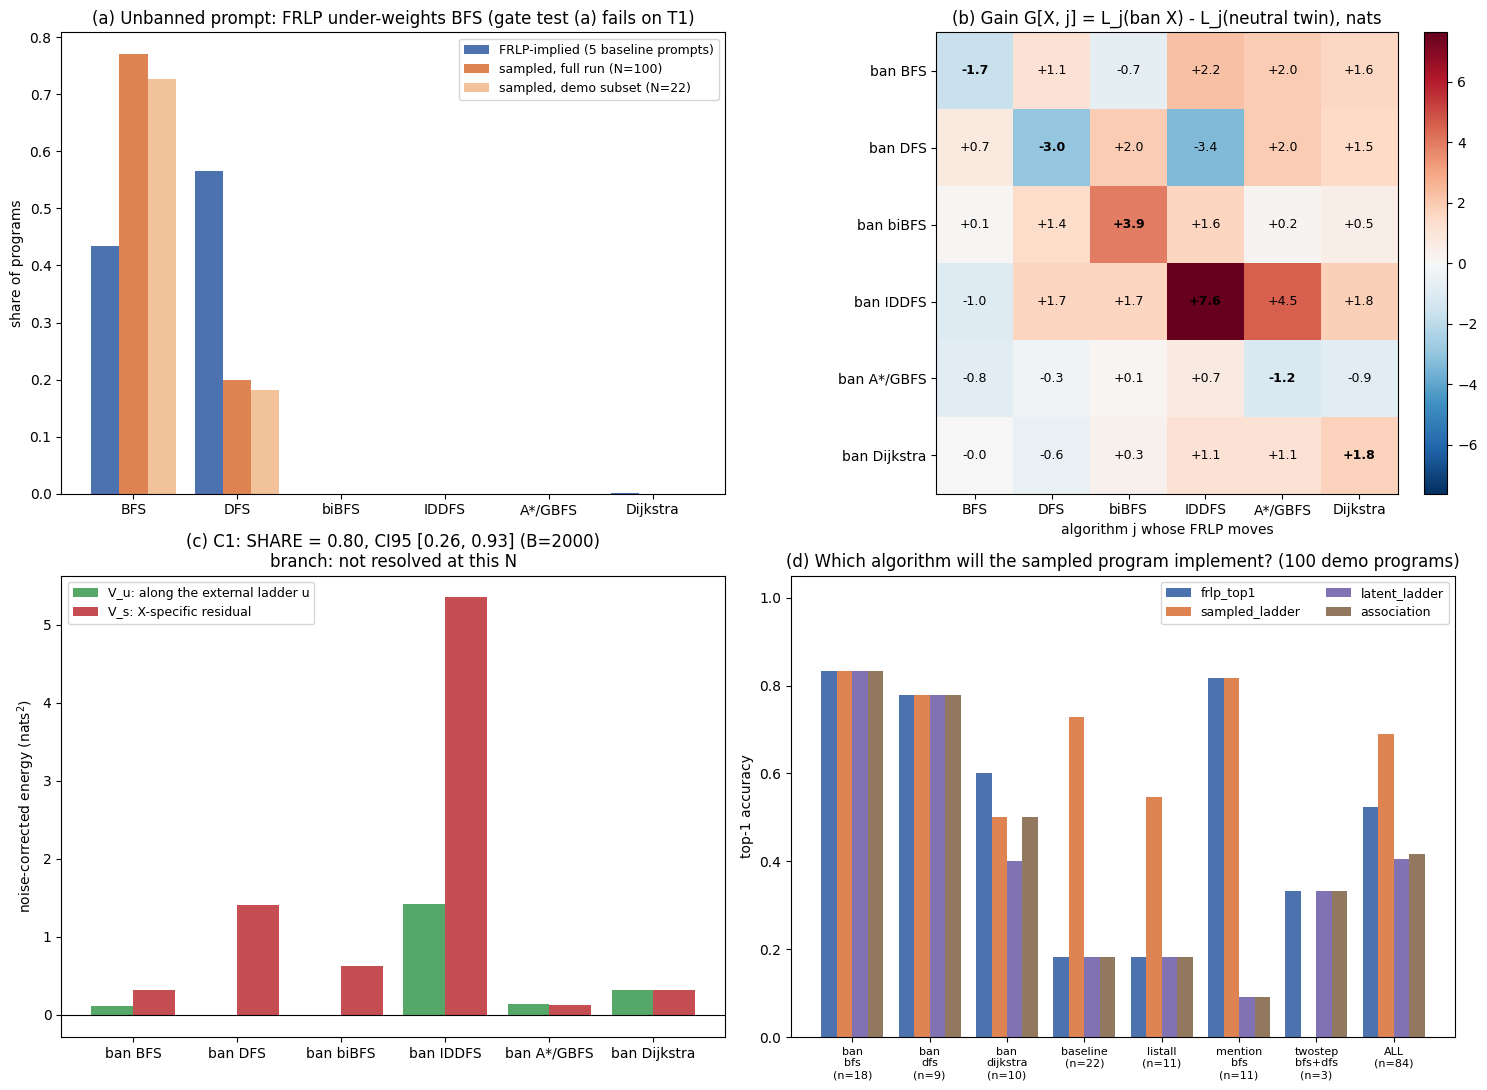

In [22]:
# ---- figures
v = views["t1"]
algs = v.td.algs
names = {"bfs": "BFS", "dfs": "DFS", "bibfs": "biBFS", "iddfs": "IDDFS", "astar_gbfs": "A*/GBFS", "dijkstra": "Dijkstra"}
labels_ = [names[j] for j in algs]
xa = np.arange(len(algs))
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# (a) FRLP-implied vs sampled distribution under the unbanned prompts (= gate test (a): implied_j = mean_s exp(L_j(s)) / sigma_s)
ax = axes[0, 0]
sig = [float(np.nansum(np.exp(v.a(f"baseline:s{s}", algs)))) for s in range(5)]
implied = np.array([np.mean([np.exp(v.a(f"baseline:s{s}", [j])[0]) / sig[s] for s in range(5)]) for j in algs])
coll = pub["results/collapse.json"]["t1"]["attempted_counts"]
sampled_full = np.array([coll.get(j, 0) for j in algs]) / sum(coll.values())
demo_base = collections.Counter(e["label"] for e in data["examples"][:N_EXAMPLES] if e["kind"] == "baseline" and e["label"] != "no_code")
sampled_demo = np.array([demo_base.get(j, 0) for j in algs]) / max(1, sum(demo_base.values()))
ax.bar(xa - 0.27, implied, 0.27, label="FRLP-implied (5 baseline prompts)", color="#4C72B0")
ax.bar(xa, sampled_full, 0.27, label=f"sampled, full run (N={sum(coll.values())})", color="#DD8452")
ax.bar(xa + 0.27, sampled_demo, 0.27, label=f"sampled, demo subset (N={sum(demo_base.values())})", color="#F2C29B")
ax.set_xticks(xa, labels_)
ax.set_ylabel("share of programs")
ax.set_title("(a) Unbanned prompt: FRLP under-weights BFS (gate test (a) fails on T1)")
ax.legend(fontsize=9)

# (b) ban-gain landscape: G[X, j] averaged over 5 templates x 2 halves (diagonal = own-drop D_X)
ax = axes[0, 1]
Gm = np.array([np.nanmean([v.G(X, w, h, algs) for w in v.tw for h in HALVES], axis=0) for X in algs])
lim = float(np.nanmax(np.abs(Gm)))
im = ax.imshow(Gm, cmap="RdBu_r", vmin=-lim, vmax=lim)
for i in range(len(algs)):
    for j in range(len(algs)):
        ax.text(j, i, f"{Gm[i, j]:+.1f}", ha="center", va="center", fontsize=9,
                fontweight="bold" if i == j else "normal")
ax.set_xticks(xa, labels_)
ax.set_yticks(xa, [f"ban {s_}" for s_ in labels_])
ax.set_xlabel("algorithm j whose FRLP moves")
ax.set_title("(b) Gain G[X, j] = L_j(ban X) - L_j(neutral twin), nats")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

# (c) C1 per banned algorithm (neutral reference): noise-corrected ladder vs X-specific energy
ax = axes[1, 0]
rows_n = res["neutral"]["per_task"]["t1"]["rows"]
xr = np.arange(len(rows_n))
ax.bar(xr - 0.2, [r_["V_u"] for r_ in rows_n], 0.4, label="V_u: along the external ladder u", color="#55A868")
ax.bar(xr + 0.2, [r_["V_s"] for r_ in rows_n], 0.4, label="V_s: X-specific residual", color="#C44E52")
ax.axhline(0, color="k", lw=0.8)
ax.set_xticks(xr, [f"ban {names[r_['X']]}" for r_ in rows_n])
ax.set_ylabel("noise-corrected energy (nats$^2$)")
bn = branches["neutral"]["pooled"]
ax.set_title(f"(c) C1: SHARE = {bn['SHARE']:.2f}, CI95 [{bn['SHARE_ci95'][0]:.2f}, {bn['SHARE_ci95'][1]:.2f}] (B={B})\n"
             f"branch: {bn['branch']}")
ax.legend(fontsize=9)

# (d) per-event top-1 accuracy of the four predictors on the demo programs
ax = axes[1, 1]
evs_d = [k for k in pc if not k.startswith("_") and k not in ("ALL", "SINGLE_BANS")] + ["ALL"]
xe = np.arange(len(evs_d))
for i, (c, col) in enumerate(zip(acc_cols, ["#4C72B0", "#DD8452", "#8172B3", "#937860"])):
    ax.bar(xe + (i - 1.5) * 0.2, [pc[ev][c] for ev in evs_d], 0.2, label=c[4:], color=col)
ax.set_xticks(xe, [(ev.split("|", 1)[1] if "|" in ev else ev).replace("|None", "").replace("|", "\n") + f"\n(n={pc[ev]['n']})"
                    for ev in evs_d],
              fontsize=8)
ax.set_ylim(0, 1.05)
ax.set_ylabel("top-1 accuracy")
ax.set_title(f"(d) Which algorithm will the sampled program implement? ({N_EXAMPLES} demo programs)")
ax.legend(fontsize=9, ncol=2)

plt.tight_layout()
plt.show()